# Multi‑Task Student with U‑Net Organ Decoder

**Folder layout**
- Images: `IMG_ROOT/<class_name>/image/<image_id>.png`
- Masks:  `IMG_ROOT/<class_name>/mask/<image_id>.png`

**Mask semantics**
- For most classes: masks are **lung masks**.
- For **pneumothorax** class: masks are **lesion masks** (pneumothorax region), **not** whole-lung masks.


In [1]:

import os, math, json, random, warnings
from typing import Optional, Tuple, Dict

import numpy as np
import pandas as pd

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights

try:
    from torchmetrics.classification import MulticlassAUROC, MulticlassAveragePrecision
except Exception as e:
    raise RuntimeError("Please install torchmetrics: pip install torchmetrics") from e

import matplotlib.pyplot as plt
from PIL import Image

# ==== DATA PATHS (EDIT THESE) ====
IMG_ROOT = "chexray"               # Root containing <class_name>/{image,mask}/<image_id>.png
TRAIN_CSV = "chexray/balanced_train.csv"   # Columns: image_id, class_id, class_name, has_mask, initial_class_id, initial_class_name, source
VAL_CSV   = "chexray/balanced_val.csv"
TEST_CSV  = "chexray/balanced_test.csv"

# Derive class list and mapping from CSV
_tmp = pd.read_csv(TRAIN_CSV)
_id2name = dict(_tmp[['class_id','class_name']].drop_duplicates().sort_values('class_id').values)
CLASS_NAMES = [ _id2name[i] for i in sorted(_id2name.keys()) ]
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_IDX = {c:i for i,c in enumerate(CLASS_NAMES)}

print("Classes:", CLASS_NAMES)
print("NUM_CLASSES:", NUM_CLASSES)

# Identify pneumothorax class index for lesion supervision
PNX_NAME_CANDIDATES = ["pneumothorax", "Pneumothorax", "PNX"]
PNX_INDEX = None
for nm in PNX_NAME_CANDIDATES:
    if nm in CLASS_TO_IDX:
        PNX_INDEX = CLASS_TO_IDX[nm]
        break
if PNX_INDEX is None and "pneumothorax" in [s.lower() for s in CLASS_NAMES]:
    PNX_INDEX = [s.lower() for s in CLASS_NAMES].index("pneumothorax")
print("Pneumothorax class index:", PNX_INDEX)

# ==== General Config ====
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

IMG_SIZE = 320  # images already 320x320

# Training hyperparams
USE_KD = False
TEACHER_WEIGHTS = "teacher.pt"
BATCH_SIZE = 16
LR = 3e-4
WEIGHT_DECAY = 1e-4
EPOCHS = 30
PATIENCE = 5
RESUME = False                 # set True to resume
CKPT_LAST = "checkpoint_last.pt"
SAVE_EVERY_EPOCH = True       # set True if you want checkpoint_epoch_XXX.pt files too


# Loss weights
ALPHA_KD   = 0.5
TEMP_KD    = 4.0
LAMBDA_ORG = 0.5   # lung organ supervision (when lung masks exist)
LAMBDA_ROI = 0.1   # penalize heatmap energy outside predicted lungs
LAMBDA_HM  = 0.7   # lesion supervision weight for pneumothorax heatmap channel (when lesion mask exists)
THRESH_LUNG = 0.5  # threshold for organ mask when computing ROI prior

FIGSIZE = (12, 8)

CKPT_GLOB = "checkpoint_epoch_*.pt"  # e.g., "ckpts/epoch_*.pt"
DEVICE = device  # reuse your notebook's 'device'
K = len(CLASS_NAMES)

Classes: ['normal', 'covid', 'pneumonia', 'pneumothorax', 'tuberculosis']
NUM_CLASSES: 5
Pneumothorax class index: 3
Device: mps


# Metrics definition

In [2]:
# regex-based fallback: extract the last integer in the filename (e.g., "..._epoch_12.pt" -> 12)
def _epoch_from_name(path: str) -> int:
    m = re.search(r'(\d+)(?=[^\d]*\.pt$)', os.path.basename(path))
    return int(m.group(1)) if m else -1


def _safe_auroc(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)
    if y_true.sum() == 0 or y_true.sum() == len(y_true):
        return np.nan
    try:
        return float(roc_auc_score(y_true, y_score))
    except Exception:
        return np.nan

def _safe_auprc(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)
    if y_true.sum() == 0:
        return np.nan
    try:
        return float(average_precision_score(y_true, y_score))
    except Exception:
        return np.nan

def _sigmoid_np(x): 
    return 1/(1+np.exp(-x))

def dice_iou_from_logits(pred_logit_or_prob, gt_mask, thr=0.5):
    pred = (pred_logit_or_prob >= thr).astype(np.uint8)
    gt   = (gt_mask > 0.5).astype(np.uint8)
    inter = (pred & gt).sum()
    ps, gs = pred.sum(), gt.sum()
    union = ps + gs - inter
    if ps + gs == 0:
        return np.nan, np.nan
    dice = 2*inter / (ps + gs + 1e-9)
    iou  = inter / (union + 1e-9)
    return float(dice), float(iou)


def dice_loss_binary(logits, target, eps:float=1e-6):
    p = torch.sigmoid(logits)
    num = 2*(p*target).sum(dim=(2,3)) + eps
    den = (p*p).sum(dim=(2,3)) + (target*target).sum(dim=(2,3)) + eps
    return 1 - (num/den).mean()

bce_logits = nn.BCEWithLogitsLoss()

def organ_loss(organs_logits, lung_mask):
    lung_logits = organs_logits[:, 1:2]  # [bg, lung, heart]
    return 0.5 * dice_loss_binary(lung_logits, lung_mask) + 0.5 * bce_logits(lung_logits, lung_mask)

def lesion_heatmap_loss(heatmap_logits, lesion_mask):
    return 0.5 * dice_loss_binary(heatmap_logits, lesion_mask) + 0.5 * bce_logits(heatmap_logits, lesion_mask)

def dice_coefficient_from_probs(probs: torch.Tensor, target: torch.Tensor, eps: float = 1e-6):
    # probs, target: (B,1,H,W) in [0,1]
    num = 2*(probs*target).sum(dim=(2,3)) + eps
    den = (probs*probs).sum(dim=(2,3)) + (target*target).sum(dim=(2,3)) + eps
    return (num/den)  # (B,)

def iou_from_binary(pred_bin: torch.Tensor, target_bin: torch.Tensor, eps: float = 1e-6):
    # pred_bin, target_bin: (B,1,H,W) in {0,1}
    inter = (pred_bin*target_bin).sum(dim=(2,3))
    union = (pred_bin + target_bin - pred_bin*target_bin).sum(dim=(2,3))
    return (inter + eps) / (union + eps)  # (B,)


In [3]:
from PIL import Image

# PIL>=10 renamed constants; this keeps it compatible with older versions too
try:
    RESAMPLE_BILINEAR = Image.Resampling.BILINEAR
except AttributeError:
    RESAMPLE_BILINEAR = Image.BILINEAR

class ConditionalResize:
    """Resize only if image.size != target size."""
    def __init__(self, size):
        # allow int or (h,w)/(w,h); PIL expects (width, height)
        if isinstance(size, (tuple, list)):
            if len(size) != 2:
                raise ValueError("size must be int or tuple/list of length 2")
            # accept either (H,W) or (W,H); normalize to (W,H)
            self.size = (int(size[1]), int(size[0])) if size[0] == size[1] else (int(size[0]), int(size[1]))
        else:
            self.size = (int(size), int(size))  # (W,H)

    def __call__(self, img: Image.Image):
        # img.size is (W,H)
        return img if img.size == self.size else img.resize(self.size, RESAMPLE_BILINEAR)


In [4]:

class StudentDataset(Dataset):
    def __init__(self, csv_path: str, img_size=320, aug=False):
        self.df = pd.read_csv(csv_path)
        self.img_size = img_size
        self.aug = aug

        req = {"image_id","class_id","class_name","has_mask"}
        missing = req - set(self.df.columns)
        if missing:
            raise ValueError(f"Missing columns in CSV: {missing}")

        self.df["class_id"] = self.df["class_id"].astype(int)
        self.df["has_mask"] = self.df["has_mask"].astype(int)
        self.df["class_name"] = self.df["class_name"].astype(str)

        base = []
        if self.aug:
            base += [
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.RandomRotation(degrees=5),
            ]
        base += [
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5]),
        ]
        self.tf = transforms.Compose([
            transforms.Grayscale(num_output_channels=3),
            ConditionalResize(IMG_SIZE),
            *base
        ])

    def _image_path(self, class_name, image_id):
        return os.path.join(IMG_ROOT, str(class_name), "image", f"{str(image_id)}.png")

    def _mask_path(self, class_name, image_id):
        return os.path.join(IMG_ROOT, str(class_name), "mask", f"{str(image_id)}.png")

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        cname = row["class_name"]
        img_path = self._image_path(cname, row["image_id"])
        if not os.path.exists(img_path):
            return None

        img = Image.open(img_path).convert("L")
        x = self.tf(img)

        y = int(row["class_id"])

        has_mask = int(row["has_mask"])
        lung_mask_t = None
        lesion_mask_t = None
        if has_mask == 1:
            mpath = self._mask_path(cname, row["image_id"])
            if os.path.exists(mpath):
                m = Image.open(mpath).convert("L").resize((self.img_size, self.img_size))
                m = np.array(m, dtype=np.float32) / 255.0
                m = (m >= 0.5).astype(np.float32)
                # pneumothorax lesion mask vs lung mask
                if PNX_INDEX is not None and y == PNX_INDEX:
                    lesion_mask_t = torch.from_numpy(m)[None, ...]
                else:
                    lung_mask_t = torch.from_numpy(m)[None, ...]
            else:
                has_mask = 0

        return {
            "image": x,
            "label": torch.tensor(y, dtype=torch.long),
            "has_mask": torch.tensor(has_mask, dtype=torch.bool),
            "lung_mask": lung_mask_t,
            "lesion_mask": lesion_mask_t,
        }

def collate_no_none(batch):
    batch = [b for b in batch if b is not None]
    if len(batch) == 0:
        return None
    images  = torch.stack([b["image"] for b in batch], dim=0)
    labels  = torch.stack([b["label"] for b in batch], dim=0)
    hasmask = torch.stack([b["has_mask"] for b in batch], dim=0)

    H, W = images.shape[-2:]
    lung_masks = None
    lesion_masks = None

    if any(b["lung_mask"] is not None for b in batch):
        lung_masks = torch.zeros((len(batch), 1, H, W), dtype=torch.float32)
        for i, b in enumerate(batch):
            if b["lung_mask"] is not None:
                lung_masks[i] = b["lung_mask"]

    if any(b["lesion_mask"] is not None for b in batch):
        lesion_masks = torch.zeros((len(batch), 1, H, W), dtype=torch.float32)
        for i, b in enumerate(batch):
            if b["lesion_mask"] is not None:
                lesion_masks[i] = b["lesion_mask"]

    return {"image": images, "label": labels, "has_mask": hasmask, "lung_mask": lung_masks, "lesion_mask": lesion_masks}


In [5]:

class ConvBNAct(nn.Module):
    def __init__(self, in_ch, out_ch, k=1, s=1, p=0):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, k, s, p, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.block(x)

class UpCatBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv1 = ConvBNAct(in_ch + skip_ch, out_ch, 3, 1, 1)
        self.conv2 = ConvBNAct(out_ch, out_ch, 3, 1, 1)
        self.skip_ch = skip_ch
    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is None:
            B, _, H, W = x.shape
            skip = x.new_zeros((B, self.skip_ch, H, W))
        elif skip.shape[-2:] != x.shape[-2:]:
            skip = F.interpolate(skip, size=x.shape[-2:], mode="bilinear", align_corners=False)
        x = torch.cat([x, skip], dim=1)
        x = self.conv1(x)
        return self.conv2(x)

class StudentMultiTask(nn.Module):
    def __init__(self, num_classes=5, out_size=320):
        super().__init__()
        self.K = num_classes
        self.out_size = out_size

        m = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.IMAGENET1K_V1)
        self.features = m.features
        # ✅ Use the actual final channel count of the backbone (usually 1280 for v2-s)
        in_ch = m.classifier[1].in_features
        self.neck = ConvBNAct(in_ch, 512, k=1)

        self.laterals = nn.ModuleDict()
        self.skip_dims = {"s3": 256, "s2": 128, "s1": 64}

        self.up3 = UpCatBlock(in_ch=512, skip_ch=self.skip_dims["s3"], out_ch=256)
        self.up2 = UpCatBlock(in_ch=256, skip_ch=self.skip_dims["s2"], out_ch=128)
        self.up1 = UpCatBlock(in_ch=128, skip_ch=self.skip_dims["s1"], out_ch=64)
        self.up0 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            ConvBNAct(64, 32, 3, 1, 1),
            ConvBNAct(32, 32, 3, 1, 1),
        )
        self.organs_head = nn.Conv2d(32, 3, kernel_size=1)  # [bg, lung, heart]

        self.hm_1x1 = nn.Conv2d(512, self.K, kernel_size=1)

        self.cls_proj = nn.Conv2d(512, 256, kernel_size=1)
        self.classifier = nn.Linear(256*self.K, self.K)

    def _ensure_lateral(self, key: str, in_ch: int, device=None):
        if key not in self.laterals:
            mod = ConvBNAct(in_ch, self.skip_dims[key], k=1)
            if device is not None:
                mod = mod.to(device)   # <-- move newly created module to the right device
            self.laterals.add_module(key, mod)

    def forward(self, x):
        B, _, H, W = x.shape
        dev = x.device

        feats = []
        out = x
        last_hw = None
        for layer in self.features:
            out = layer(out)
            hw = out.shape[-2:]
            if last_hw is None or hw != last_hw:
                feats.append(out)
                last_hw = hw

        # ✅ This is the real deepest feature map (final layer output)
        deepest = out

        # Skips from the last resolution-change points (if available)
        skip3 = feats[-1] if len(feats) >= 1 else None
        skip2 = feats[-2] if len(feats) >= 2 else None
        skip1 = feats[-3] if len(feats) >= 3 else None

        Fdeep = self.neck(deepest)                   # now channels match in_ch
        M = self.hm_1x1(Fdeep)                       # (B,K,h,w)
        M_up = F.interpolate(M, size=(H, W), mode="bilinear", align_corners=False)
        heatmaps = torch.sigmoid(M_up)

        # create lateral modules on-the-fly, ON THE RIGHT DEVICE
        s3p = s2p = s1p = None
        if skip3 is not None:
            self._ensure_lateral("s3", skip3.shape[1], device=dev); s3p = self.laterals["s3"](skip3)
        if skip2 is not None:
            self._ensure_lateral("s2", skip2.shape[1], device=dev); s2p = self.laterals["s2"](skip2)
        if skip1 is not None:
            self._ensure_lateral("s1", skip1.shape[1], device=dev); s1p = self.laterals["s1"](skip1)


        # project skips lazily
        #s3p = s2p = s1p = None
        #if skip3 is not None:
        #    self._ensure_lateral("s3", skip3.shape[1]); s3p = self.laterals["s3"](skip3)
        #if skip2 is not None:
        #    self._ensure_lateral("s2", skip2.shape[1]); s2p = self.laterals["s2"](skip2)
        #if skip1 is not None:
        #    self._ensure_lateral("s1", skip1.shape[1]); s1p = self.laterals["s1"](skip1)

        d3 = self.up3(Fdeep, s3p)
        d2 = self.up2(d3, s2p)
        d1 = self.up1(d2, s1p)
        d0 = self.up0(d1)
        organs = self.organs_head(d0)
        organs = F.interpolate(organs, size=(H, W), mode="bilinear", align_corners=False)

        Fcls = self.cls_proj(Fdeep)
        Msig = torch.sigmoid(M)
        pooled = []
        for k in range(self.K):
            wmap = Msig[:, k:k+1]
            pk = (Fcls * wmap).mean(dim=[2,3])
            pooled.append(pk)
        P = torch.cat(pooled, dim=1)
        logits = self.classifier(P)

        return {"logits": logits, "heatmaps": heatmaps, "organs": organs, "heatmaps_logits": M_up}
    


In [6]:

class IdentityTeacher(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        m = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.IMAGENET1K_V1)
        self.features = m.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(m.classifier[1].in_features, num_classes)
    def forward(self, x):
        f = self.features(x)
        z = self.pool(f).flatten(1)
        return {"logits": self.fc(z)}


In [7]:

import sys, os

PIN = (device == "cuda")
NUM_WORKERS = 0  # notebook-safe
train_ds = StudentDataset(TRAIN_CSV, img_size=IMG_SIZE, aug=True)
val_ds   = StudentDataset(VAL_CSV,   img_size=IMG_SIZE, aug=False)
test_ds  = StudentDataset(TEST_CSV,  img_size=IMG_SIZE, aug=False)

train_dl = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN,
    collate_fn=collate_no_none, drop_last=False
)
val_dl = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN,
    collate_fn=collate_no_none, drop_last=False
)
test_dl = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN,
    collate_fn=collate_no_none, drop_last=False
)


batch = next(iter(train_dl))
shapes = {k: (None if v is None else tuple(v.shape) if hasattr(v,'shape') else type(v)) for k,v in batch.items()}
print("Batch shapes:", shapes)


Batch shapes: {'image': (16, 3, 320, 320), 'label': (16,), 'has_mask': (16,), 'lung_mask': (16, 1, 320, 320), 'lesion_mask': (16, 1, 320, 320)}


In [8]:

net = StudentMultiTask(num_classes=NUM_CLASSES, out_size=IMG_SIZE).to(device)

opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)

ce = nn.CrossEntropyLoss()

auroc_macro = MulticlassAUROC(num_classes=NUM_CLASSES, average="macro").to(device)
auprc_macro = MulticlassAveragePrecision(num_classes=NUM_CLASSES, average="macro").to(device)
auroc_pc = MulticlassAUROC(num_classes=NUM_CLASSES, average=None).to(device)
auprc_pc = MulticlassAveragePrecision(num_classes=NUM_CLASSES, average=None).to(device)

kd_criterion = nn.KLDivLoss(reduction="batchmean")
teacher = None
if USE_KD:
    teacher = IdentityTeacher(num_classes=NUM_CLASSES).to(device)
    if os.path.exists(TEACHER_WEIGHTS):
        teacher.load_state_dict(torch.load(TEACHER_WEIGHTS, map_location=device))
    teacher.eval()
    for p in teacher.parameters(): p.requires_grad = False


# Training epochs

In [9]:
start_epoch = 0
best_val, bad = -1e9, 0

if RESUME and os.path.exists(CKPT_LAST):
    ckpt = torch.load(CKPT_LAST, map_location=device, weights_only=False)
    net.load_state_dict(ckpt["model"])
    opt.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    best_val    = ckpt.get("best_val", best_val)
    start_epoch = ckpt.get("epoch", 0)

    # restore RNG states (best-effort)
    try:
        import random, numpy as np, torch
        random.setstate(ckpt["py_random"])
        np.random.set_state(ckpt["np_random"])
        torch.set_rng_state(ckpt["torch_rng_state"])
    except Exception:
        pass

    # ensure optimizer state tensors are on the right device
    for state in opt.state.values():
        for k, v in state.items():
            if isinstance(v, torch.Tensor):
                state[k] = v.to(device)

    print(f"Resumed from {CKPT_LAST} at epoch {start_epoch}")

In [ ]:

for epoch in range(start_epoch, EPOCHS):
    net.train()
    tr_loss = 0.0; ntr = 0
    
    for batch in train_dl:
        if batch is None: continue
        xb = batch["image"].to(device)
        yb = batch["label"].to(device)
        hasmask = batch["has_mask"].to(device)
        lung_mask = batch["lung_mask"]
        lesion_mask = batch["lesion_mask"]
        if lung_mask is not None:   lung_mask = lung_mask.to(device)
        if lesion_mask is not None: lesion_mask = lesion_mask.to(device)
        
        out = net(xb)
        logits = out["logits"]
        organs = out["organs"]
        heatmaps = out["heatmaps"]             # sigmoid maps (B,K,H,W)
        hm_logits_up = out["heatmaps_logits"]  # raw logits per class (B,K,H,W)
        
        loss_cls = ce(logits, yb)
        
        if USE_KD and teacher is not None:
            with torch.no_grad():
                t_logits = teacher(xb)["logits"]
            s_logp_T = (logits / TEMP_KD).log_softmax(dim=1)
            t_p_T    = (t_logits / TEMP_KD).softmax(dim=1)
            loss_kd = kd_criterion(s_logp_T, t_p_T) * (TEMP_KD * TEMP_KD)
        else:
            loss_kd = 0.0
        
        if lung_mask is not None and hasmask.any():
            idx_lung = (lung_mask.view(lung_mask.size(0), -1).sum(dim=1) > 0).nonzero(as_tuple=True)[0]
            if idx_lung.numel() > 0:
                loss_org = organ_loss(organs[idx_lung], lung_mask[idx_lung])
            else:
                loss_org = 0.0
        else:
            loss_org = 0.0
        
        if PNX_INDEX is not None and lesion_mask is not None:
            idx_les = (lesion_mask.view(lesion_mask.size(0), -1).sum(dim=1) > 0).nonzero(as_tuple=True)[0]
            if idx_les.numel() > 0:
                pnx_hm_logits = hm_logits_up[idx_les, PNX_INDEX:PNX_INDEX+1, :, :]
                loss_hm = lesion_heatmap_loss(pnx_hm_logits, lesion_mask[idx_les])
            else:
                loss_hm = 0.0
        else:
            loss_hm = 0.0
        
        lungs_soft = torch.sigmoid(organs[:,1:2])
        outside = 1.0 - (lungs_soft >= THRESH_LUNG).float()
        hm_sum = heatmaps.sum(dim=1, keepdim=True)
        loss_roi = (hm_sum * outside).mean()
        
        loss = (1-ALPHA_KD)*loss_cls + ALPHA_KD*loss_kd + LAMBDA_ORG*loss_org + LAMBDA_ROI*loss_roi + LAMBDA_HM*loss_hm
        
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        
        tr_loss += loss.item() * yb.size(0)
        ntr += yb.size(0)
    
    tr_loss /= max(ntr, 1)
    
    net.eval()
    val_loss = 0.0; nva = 0
    auroc_macro.reset(); auprc_macro.reset(); auroc_pc.reset(); auprc_pc.reset()
    
    dice_lung_sum = 0.0; iou_lung_sum = 0.0; n_lung_batches = 0
    dice_pnx_sum  = 0.0; iou_pnx_sum  = 0.0; n_pnx_batches  = 0

    with torch.inference_mode():
        _ = net(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=device))
        for batch in val_dl:
            if batch is None: continue
            xb = batch["image"].to(device)
            yb = batch["label"].to(device)
            out = net(xb)
            
            organs = out["organs"]                   # (B,3,H,W) logits
            hm_logits_up = out["heatmaps_logits"]    # (B,K,H,W) logits for class heatmaps

            # Lung segmentation metrics on the subset that actually has lung masks
            lm = batch.get("lung_mask", None)
            if lm is not None:
                lm = lm.to(device)
                idx = (lm.flatten(1).sum(1) > 0).nonzero(as_tuple=True)[0]
                if idx.numel() > 0:
                    lung_prob = torch.sigmoid(organs[idx, 1:2])                  # (b,1,H,W)
                    dice = dice_coefficient_from_probs(lung_prob, lm[idx]).mean().item()
                    iou  = iou_from_binary((lung_prob >= 0.5).float(), lm[idx]).mean().item()
                    dice_lung_sum += dice; iou_lung_sum += iou; n_lung_batches += 1

            # Pneumothorax lesion metrics on the subset that has lesion masks
            les = batch.get("lesion_mask", None)
            if PNX_INDEX is not None and les is not None:
                les = les.to(device)
                idx = (les.flatten(1).sum(1) > 0).nonzero(as_tuple=True)[0]
                if idx.numel() > 0:
                    pnx_prob = torch.sigmoid(hm_logits_up[idx, PNX_INDEX:PNX_INDEX+1])
                    dice = dice_coefficient_from_probs(pnx_prob, les[idx]).mean().item()
                    iou  = iou_from_binary((pnx_prob >= 0.5).float(), les[idx]).mean().item()
                    dice_pnx_sum += dice; iou_pnx_sum += iou; n_pnx_batches += 1

            logits = out["logits"]
            loss = ce(logits, yb)
            val_loss += loss.item() * yb.size(0); nva += yb.size(0)
            
            probs = logits.softmax(1)
            auroc_macro.update(probs, yb); auprc_macro.update(probs, yb)
            auroc_pc.update(probs, yb);   auprc_pc.update(probs, yb)
    
    val_loss /= max(nva, 1)
    val_auroc = float(auroc_macro.compute())
    val_auprc = float(auprc_macro.compute())
    auc_pc     = auroc_pc.compute().detach().cpu().numpy()
    auprc_pc_v = auprc_pc.compute().detach().cpu().numpy()

    ckpt = {
        "epoch": epoch + 1,                     # next epoch to run
        "model": net.state_dict(),
        "optimizer": opt.state_dict(),
        "scheduler": scheduler.state_dict(),
        "best_val": best_val,
        "py_random": random.getstate(),
        "np_random": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
    }

    torch.save(ckpt, CKPT_LAST)
    if SAVE_EVERY_EPOCH:
        torch.save(ckpt, f"checkpoint_epoch_{epoch+1:03d}.pt")
    
    print(f"Epoch {epoch+1:02d} | train_loss {tr_loss:.4f} | val_loss {val_loss:.4f} | AUROC {val_auroc:.3f} | AUPRC {val_auprc:.3f}")
    for c, (a, p) in enumerate(zip(auc_pc, auprc_pc_v)):
        print(f"  - {CLASS_NAMES[c]:14s} | AUROC {a:.3f} | AUPRC {p:.3f}")
    
    print(f"Best macro AUROC: {best_val:.3f} (weights saved to best.pt)")
    if n_lung_batches > 0:
        print(f"  Lung seg (val): Dice={dice_lung_sum/n_lung_batches:.3f} | IoU@0.5={iou_lung_sum/n_lung_batches:.3f} | batches={n_lung_batches}")
    if n_pnx_batches > 0:
        print(f"  PNX heatmap (val): Dice={dice_pnx_sum/n_pnx_batches:.3f} | IoU@0.5={iou_pnx_sum/n_pnx_batches:.3f} | batches={n_pnx_batches}")


    scheduler.step(val_auroc)
    if val_auroc > best_val:
        best_val, bad = val_auroc, 0
        torch.save(net.state_dict(), "best.pt")
    else:
        bad += 1
        if bad >= PATIENCE:
            print("Early stopping.")
            break




# CAM Helper

In [10]:
import torch.nn.functional as F

def compute_cams(model, x, class_indices, out_size: int):
    """
    model: StudentMultiTask with attributes .features and .classifier
    x: [1,3,H,W] preprocessed input
    class_indices: iterable of label indices (e.g., range(NUM_CLASSES))
    returns: np.array [len(class_indices), out_size, out_size]
    """
    with torch.no_grad():
        feats = model.features(x)                  # [1, C, h, w]
        W = model.classifier.weight                # [K, C]
        cams = []
        for c in class_indices:
            w = W[c].view(1, -1, 1, 1)            # [1, C, 1, 1]
            cam = (feats * w).sum(dim=1, keepdim=True)  # [1,1,h,w]
            cam = F.relu(cam)                      # ReLU for CAM
            cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE),
                                 mode="bilinear", align_corners=False)
            cams.append(cam)
        cams = torch.cat(cams, dim=1)              # [1, K, H, W]
    cams = cams.squeeze(0).cpu().numpy()
    # min-max per class for display
    cams = (cams - cams.min(axis=(1,2), keepdims=True)) / \
           (np.ptp(cams, axis=(1,2), keepdims=True) + 1e-6)
    return cams


In [29]:


from torchsummary import summary
from torchinfo import summary
import pytorch_model_summary as pms

## Model Summary
summary(net, (1, 3, IMG_SIZE, IMG_SIZE))
#display(net)



Layer (type:depth-idx)                                  Output Shape              Param #
StudentMultiTask                                        [1, 5, 320, 320]          --
├─Sequential: 1-1                                       --                        --
│    └─Conv2dNormActivation: 2-1                        [1, 24, 160, 160]         --
│    │    └─Conv2d: 3-1                                 [1, 24, 160, 160]         648
│    │    └─BatchNorm2d: 3-2                            [1, 24, 160, 160]         48
│    │    └─SiLU: 3-3                                   [1, 24, 160, 160]         --
│    └─Sequential: 2-2                                  [1, 24, 160, 160]         --
│    │    └─FusedMBConv: 3-4                            [1, 24, 160, 160]         5,232
│    │    └─FusedMBConv: 3-5                            [1, 24, 160, 160]         5,232
│    └─Sequential: 2-3                                  [1, 48, 80, 80]           --
│    │    └─FusedMBConv: 3-6                         

# Evaluation for one checkpoint (forward-only)

In [14]:
@torch.no_grad()
def evaluate_one_ckpt(weights_path, val_loader, class_names=CLASS_NAMES, img_size=IMG_SIZE):
    model = safe_load_for_eval(weights_path, num_classes=len(class_names), img_size=img_size)

    # buffers
    y_true = [[] for _ in class_names]
    y_prob = [[] for _ in class_names]
    lung_dice_list, lung_iou_list = [], []
    pnx_dice_list,  pnx_iou_list  = [], []

    # debug counters
    n_batches = 0
    n_lung_total = 0
    n_pnx_with_mask = 0
    class_counts = np.zeros(len(class_names), dtype=int)

    # keys in your loader
    def extract_batch(batch):
        x        = batch["image"]                 # [B,3,H,W]
        y        = batch["label"]                 # [B] indices
        lung     = batch.get("lung_mask", None)   # [B,1,H,W]
        lesion   = batch.get("lesion_mask", None) # [B,1,H,W]
        has_mask = batch.get("has_mask", None)    # [B]
        return x, y, lung, lesion, has_mask

    APPLY_INFER_TF = False  # images already (B,3,320,320)

    # pneumothorax class index
    try:
        pnx_k = [c.lower() for c in class_names].index("pneumothorax")
    except ValueError:
        pnx_k = None

    # --- auto-detect lung channel once (0 or 1) using first batch that has GT ---
    lung_channel = None

    for batch in val_loader:
        n_batches += 1
        x, y, lung, lesion, has_mask = extract_batch(batch)

        # labels -> [B,K] multi-hot and count per-class
        y = to_multihot(y, K=len(class_names))          # handles [B] indices
        lbl_idx = y.argmax(dim=1).cpu().numpy()         # for counts (single-label assumption)
        for idx in lbl_idx:
            if 0 <= idx < len(class_names):
                class_counts[idx] += 1

        if APPLY_INFER_TF:
            if torch.is_tensor(x) and x.dim()==4 and x.size(1)==1:
                x = x.repeat(1,3,1,1)
            x = (x - 0.5) / 0.5
        x = x.to(DEVICE)

        out      = model(x)
        probs    = torch.softmax(out["logits"], dim=1).cpu().numpy()   # [B,K]
        organs   = out["organs"]                                       # [B,C,H,W], C>=2 expected
        heatmaps = out["heatmaps"]                                     # [B,K,H,W]

        y_np = y.cpu().numpy().astype(int)                             # [B,K]
        for k in range(len(class_names)):
            y_true[k].extend(y_np[:, k].tolist())
            y_prob[k].extend(probs[:, k].tolist())

        # --------- LUNG segmentation ---------
        if lung is not None:
            lung = lung.cpu().numpy()                                  # [B,1,H,W]
            n_lung_total += lung.shape[0]

            # Detect lung channel the first time we have GT
            if lung_channel is None:
                # try channel 0 and 1, average Dice over this batch
                cand = []
                for ch in (0, 1):
                    if ch < organs.size(1):
                        logits = organs[:, ch].cpu().numpy()
                        ds = []
                        for b in range(lung.shape[0]):
                            prob = _sigmoid_np(logits[b])
                            d, _ = dice_iou_from_logits(prob, lung[b,0], thr=0.5)
                            if not math.isnan(d):
                                ds.append(d)
                        cand.append((np.nanmean(ds) if ds else -1, ch))
                lung_channel = max(cand)[1] if cand else 1  # default to 1
                print(f"[detect] lung_channel = {lung_channel}")

            logits = organs[:, lung_channel].cpu().numpy()
            for b in range(lung.shape[0]):
                prob = _sigmoid_np(logits[b])
                d,i = dice_iou_from_logits(prob, lung[b,0], thr=0.5)
                if not math.isnan(d): lung_dice_list.append(d)
                if not math.isnan(i): lung_iou_list.append(i)

        # --------- PNX segmentation (only where has_mask==1) ---------
        if pnx_k is not None and lesion is not None and has_mask is not None:
            lesion   = lesion.cpu().numpy()                              # [B,1,H,W]
            has_mask = has_mask.cpu().numpy().astype(int).reshape(-1)    # [B]
            pnx_logits = heatmaps[:, pnx_k].cpu().numpy()                # [B,H,W]
            for b in range(len(has_mask)):
                if has_mask[b] == 1:
                    n_pnx_with_mask += 1
                    prob = _sigmoid_np(pnx_logits[b])
                    d,i = dice_iou_from_logits(prob, lesion[b,0], thr=0.5)
                    if not math.isnan(d): pnx_dice_list.append(d)
                    if not math.isnan(i): pnx_iou_list.append(i)

    # per-class metrics
    auroc_pc = [_safe_auroc(y_true[k], y_prob[k]) for k in range(len(class_names))]
    auprc_pc = [_safe_auprc(y_true[k], y_prob[k]) for k in range(len(class_names))]
    macro_auroc = float(np.nanmean(auroc_pc)) if any(np.isfinite(auroc_pc)) else np.nan
    macro_auprc = float(np.nanmean(auprc_pc)) if any(np.isfinite(auprc_pc)) else np.nan

    metrics = {
        "macro_auroc": macro_auroc,
        "macro_auprc": macro_auprc,
        "per_class_auroc": auroc_pc,
        "per_class_auprc": auprc_pc,
        "lung_dice": float(np.nanmean(lung_dice_list)) if lung_dice_list else np.nan,
        "lung_iou":  float(np.nanmean(lung_iou_list))  if lung_iou_list  else np.nan,
        "pnx_dice":  float(np.nanmean(pnx_dice_list))  if pnx_dice_list else np.nan,
        "pnx_iou":   float(np.nanmean(pnx_iou_list))   if pnx_iou_list   else np.nan,
        # debug
        "_n_batches": n_batches,
        "_n_lung_total": n_lung_total,
        "_n_pnx_with_mask": n_pnx_with_mask,
        "_class_counts": class_counts.tolist(),
    }
    print(f"[eval: {os.path.basename(weights_path)}] "
          f"lung N={metrics['_n_lung_total']}, pnx-with-mask N={metrics['_n_pnx_with_mask']}, "
          f"class_counts={metrics['_class_counts']}")
    return metrics

# Evaluate all checkpoints

def evaluate_all_checkpoints(ckpt_glob, val_loader=None):
    records = []
    for path in sorted(glob.glob(ckpt_glob), key=_epoch_from_name):
        print(f"[eval] {path}")
        if val_loader is None:
            # try to read metrics from checkpoint only
            try:
                ckpt = torch.load(path, map_location="cpu", weights_only=False)
            except Exception:
                ckpt = {}
            if isinstance(ckpt, dict) and "macro_auprc" in ckpt and "per_class_auprc" in ckpt:
                rec = {
                    "path": path,
                    "epoch": ckpt.get("epoch", _epoch_from_name(path)),
                    "macro_auroc": float(ckpt.get("macro_auroc", np.nan)),
                    "macro_auprc": float(ckpt.get("macro_auprc", np.nan)),
                    "lung_dice": float(ckpt.get("lung_dice", np.nan)),
                    "lung_iou":  float(ckpt.get("lung_iou", np.nan)),
                    "pnx_dice":  float(ckpt.get("pnx_dice", np.nan)),
                    "pnx_iou":   float(ckpt.get("pnx_iou", np.nan)),
                    "per_class_auroc": list(map(float, ckpt["per_class_auroc"])),
                    "per_class_auprc": list(map(float, ckpt["per_class_auprc"])),
                }
            else:
                raise RuntimeError("Metrics not stored in checkpoints; provide val_loader to compute them.")
        else:
            metrics = evaluate_one_ckpt(path, val_loader, class_names=CLASS_NAMES, img_size=IMG_SIZE)
            rec = {"path": path, "epoch": _epoch_from_name(path), **metrics}
        records.append(rec)
    df = pd.DataFrame(records).sort_values("epoch").reset_index(drop=True)
    return df

import os, re, glob, math, numpy as np, pandas as pd, torch
# assumes: CLASS_NAMES, IMG_SIZE, evaluate_one_ckpt, _epoch_from_name already defined

def evaluate_all_checkpoints_force_eval(ckpt_glob, val_loader):
    paths = sorted(glob.glob(ckpt_glob), key=_epoch_from_name)
    if not paths:
        raise FileNotFoundError(f"No checkpoints matched {ckpt_glob}")
    records = []
    for p in paths:
        print(f"[eval] {p}")
        m = evaluate_one_ckpt(p, val_loader, class_names=CLASS_NAMES, img_size=IMG_SIZE)
        records.append({"path": p, "epoch": _epoch_from_name(p), **m})
    df = pd.DataFrame(records).sort_values("epoch").reset_index(drop=True)
    return df


In [15]:
## Plotting helpers

def plot_over_epochs(df):
    e = df["epoch"].values
    plt.figure(figsize=(6,4))
    plt.plot(e, df["macro_auroc"], label="macro-AUROC")
    plt.plot(e, df["macro_auprc"], label="macro-AUPRC")
    plt.ylim(0,1); plt.xlabel("epoch"); plt.ylabel("score"); plt.title("Macro metrics")
    plt.legend(); plt.grid(True, alpha=0.3); plt.show()

    if "lung_dice" in df and "pnx_dice" in df:
        plt.figure(figsize=(6,4))
        plt.plot(e, df["lung_dice"], label="lung Dice")
        plt.plot(e, df["pnx_dice"],  label="PNX Dice")
        plt.ylim(0,1); plt.xlabel("epoch"); plt.ylabel("Dice"); plt.title("Segmentation Dice")
        plt.legend(); plt.grid(True, alpha=0.3); plt.show()

    # Per-class AUPRC (if present)
    if "per_class_auprc" in df.columns and isinstance(df["per_class_auprc"].iloc[0], (list, tuple)):
        arr = np.vstack(df["per_class_auprc"].values)  # [E,K]
        plt.figure(figsize=(7,4.5))
        for k, name in enumerate(CLASS_NAMES):
            plt.plot(e, arr[:,k], label=name)
        plt.ylim(0,1); plt.xlabel("epoch"); plt.ylabel("AUPRC"); plt.title("Per-class AUPRC")
        plt.legend(ncol=2, fontsize=9); plt.grid(True, alpha=0.3); plt.show()

def plot_over_epochs_safe(df):
    e = df["epoch"].values

    # Macro curves (only if present)
    if "macro_auroc" in df.columns or "macro_auprc" in df.columns:
        import matplotlib.pyplot as plt
        plt.figure(figsize=(6,4))
        if "macro_auroc" in df: plt.plot(e, df["macro_auroc"], label="macro-AUROC")
        if "macro_auprc" in df: plt.plot(e, df["macro_auprc"], label="macro-AUPRC")
        plt.ylim(0,1); plt.xlabel("epoch"); plt.ylabel("score"); plt.title("Macro metrics")
        plt.legend(); plt.grid(True, alpha=0.3); plt.show()

    # Segmentation (if present)
    if "lung_dice" in df.columns or "pnx_dice" in df.columns:
        plt.figure(figsize=(6,4))
        if "lung_dice" in df: plt.plot(e, df["lung_dice"], label="lung Dice")
        if "pnx_dice" in df:  plt.plot(e, df["pnx_dice"],  label="PNX Dice")
        plt.ylim(0,1); plt.xlabel("epoch"); plt.ylabel("Dice"); plt.title("Segmentation Dice")
        plt.legend(); plt.grid(True, alpha=0.3); plt.show()

    # Per-class AUPRC (if present)
    if "per_class_auprc" in df.columns and isinstance(df["per_class_auprc"].iloc[0], (list, tuple)):
        import numpy as np
        arr = np.vstack(df["per_class_auprc"].values)  # [E,K]
        plt.figure(figsize=(7,4.5))
        for k, name in enumerate(CLASS_NAMES):
            plt.plot(e, arr[:,k], label=name)
        plt.ylim(0,1); plt.xlabel("epoch"); plt.ylabel("AUPRC"); plt.title("Per-class AUPRC")
        plt.legend(ncol=2, fontsize=9); plt.grid(True, alpha=0.3); plt.show()



## robust label normalizer

In [16]:


def to_multihot(y, K: int) -> torch.Tensor:
    """
    Convert various label formats to [B, K] float multi-hot:
      - [B] or [B,1] integer class indices  -> one-hot
      - [B,K] already multi-hot            -> returned as float
      - list/np arrays are converted to torch first
    """
    if not torch.is_tensor(y):
        y = torch.as_tensor(y)
    y = y.detach()

    if y.ndim == 0:
        y = y.view(1)

    # If [B,1] -> squeeze to [B]
    if y.ndim == 2 and y.size(-1) == 1:
        y = y.squeeze(-1)

    if y.ndim == 1:
        # single-label multiclass indices
        y = F.one_hot(y.long(), num_classes=K).float()
    elif y.ndim == 2 and y.size(-1) == K:
        y = y.float()
    else:
        raise ValueError(f"Unsupported label shape {tuple(y.shape)}; expected [B] or [B,K].")
    return y


In [17]:
val_loader = val_dl   # your validation DataLoader
df = evaluate_all_checkpoints_force_eval(CKPT_GLOB, val_loader)
plot_over_epochs_safe(df)



[eval] checkpoint_epoch_001.pt


NameError: name 'safe_load_for_eval' is not defined

In [ ]:
print(df[["epoch","macro_auprc","lung_dice","pnx_dice","_n_lung_total","_n_pnx_with_mask"]].head())


   epoch  macro_auprc  lung_dice  pnx_dice  _n_lung_total  _n_pnx_with_mask
0      1          NaN   0.231185  0.010341           1650               604
1      2          NaN   0.233763  0.010341           1650               604
2      3          NaN   0.233696  0.010341           1650               604
3      4          NaN   0.234565  0.010341           1650               604
4      5          NaN   0.235198  0.010341           1650               604


In [18]:
import glob

rows = collect_metrics_from_ckpts_only(CKPT_GLOB)

if not rows:
    raise FileNotFoundError(
        f"No checkpoints matched {CKPT_GLOB}. "
        "Double-check the pattern and working directory."
    )

df = pd.DataFrame(rows)

# If epoch somehow missing, create it from filename or index
if "epoch" not in df.columns:
    df["epoch"] = [ _epoch_from_name(p) for p in df["path"] ]
    if (df["epoch"] < 0).any():
        df["epoch"] = np.arange(len(df))

df = df.sort_values("epoch").reset_index(drop=True)
print(df[["epoch","path"]].head())

print("CWD:", os.getcwd())
print("GLOB:", CKPT_GLOB)
print("FILES:", sorted(glob.glob(CKPT_GLOB))[:5])
print(df.columns.tolist())
print(df.head(3).to_dict(orient="records"))

plot_over_epochs(df)



NameError: name 'collect_metrics_from_ckpts_only' is not defined

In [ ]:

infer_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5]),
])

def _resolve_weights_path(path_candidates):
    for p in path_candidates:
        if p and os.path.exists(p):
            return p
    raise FileNotFoundError(f"No weights file found in {path_candidates}")

def safe_load_for_eval(weights_path, num_classes=K, img_size=IMG_SIZE):
    model = StudentMultiTask(num_classes=num_classes, out_size=img_size).to(DEVICE)
    # warm-up to materialize lazy modules on correct device
    with torch.no_grad():
        _ = model(torch.zeros(1, 3, img_size, img_size, device=DEVICE))

    state = torch.load(weights_path, map_location=DEVICE, weights_only=False)
    if isinstance(state, dict) and "state_dict" not in state and "model" in state:
        state = state["model"]
    elif isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]

    msd = model.state_dict()
    filtered = {k: v for k, v in (state.items() if isinstance(state, dict) else [])
                if k in msd and hasattr(v, "shape") and hasattr(msd[k], "shape") and v.shape == msd[k].shape}
    model.load_state_dict(filtered, strict=False)
    model.eval()
    return model


def load_model(weights_path=None, num_classes=NUM_CLASSES, img_size=IMG_SIZE):
    
    """
    Robust loader:
    - Builds the model and moves it to the current device
    - Runs a warm-up forward to instantiate lazy 'laterals.*' modules on the right device
    - Loads either a raw state_dict or a full checkpoint dict containing 'model'
    """

    model = StudentMultiTask(num_classes=num_classes, out_size=img_size).to(device)    
    # Warm-up forward to create lazy modules (laterals) on 'device'
    with torch.no_grad():
        _ = model(torch.zeros(1, 3, img_size, img_size, device=device))

    # Pick a weights path if not provided
    if weights_path is None:
        weights_path = _resolve_weights_path([
            "best.pt",            # training saves here
            "best_model.pt",      # older/alternate name
            "checkpoint_last.pt"  # full training checkpoint
        ])

    print(f"[load_model] using weights: {weights_path}")

    state = torch.load(weights_path, map_location=device)

    # unwrap common checkpoint formats
    if isinstance(state, dict) and "state_dict" not in state and "model" in state:
        state = state["model"]
    elif isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]

    msd = model.state_dict()

    # Compute checkpoint K (for a helpful warning)
    ckpt_K = None
    for cand in ("classifier.weight", "module.classifier.weight"):
        if isinstance(state, dict) and cand in state and hasattr(state[cand], "shape"):
            ckpt_K = state[cand].shape[0]

    # Filter to keys that both exist AND have identical shapes
    filtered = {}
    mismatched = []
    for k, v in (state.items() if isinstance(state, dict) else []):
        if k in msd:
            if hasattr(v, "shape") and hasattr(msd[k], "shape") and v.shape == msd[k].shape:
                filtered[k] = v
            else:
                mismatched.append((k, tuple(getattr(v, "shape", [])), tuple(msd[k].shape)))

    missing = [k for k in msd.keys() if k not in filtered]
    unexpected = [k for k in (state.keys() if isinstance(state, dict) else []) if k not in msd]

    print(f"[load_model] loading {len(filtered)}/{len(msd)} matching tensors")
    if ckpt_K is not None and ckpt_K != num_classes:
        print(f"[load_model] WARNING: checkpoint classes={ckpt_K} != current num_classes={num_classes}. "
            "Heads with mismatched shapes were left randomly initialized.")

    if mismatched:
        print("[load_model] mismatched tensors (checkpoint_shape -> model_shape):")
        for k, s_ckpt, s_model in mismatched[:10]:
            print(f"  {k}: {s_ckpt} -> {s_model}  (showing up to 10)")

    if unexpected:
        print("[load_model] unexpected keys:", unexpected[:10], "..." if len(unexpected)>10 else "")
    if missing:
        print("[load_model] missing keys:", missing[:10], "..." if len(missing)>10 else "")

    # Load the filtered subset; allow remaining missing/unexpected
    incompatible = model.load_state_dict(filtered, strict=False)



    # Helpful printouts for debugging any residual mismatch
    if incompatible.missing_keys or incompatible.unexpected_keys:
        print("[load_model] Warning – non-empty IncompatibleKeys")
        if incompatible.missing_keys:
            print("  missing_keys:", incompatible.missing_keys[:10], "..." if len(incompatible.missing_keys)>10 else "")
        if incompatible.unexpected_keys:
            print("  unexpected_keys:", incompatible.unexpected_keys[:10], "..." if len(incompatible.unexpected_keys)>10 else "")

    model.eval()
    return model


def predict_image(
    img_path: str,
    model=None,
    alpha=0.35,         # overlay opacity for masks/heatmaps
):
    """
    Row 1: Original image | Lung mask overlay
    Row 2: Bar chart of predicted label probabilities (sorted)
    Row 3: Heatmaps for all labels (sorted from most to least probable)
    Returns:
      probs (np.ndarray[K]), heatmaps (np.ndarray[K,H,W]), organs (np.ndarray[C,H,W]), order (np.ndarray[K])
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib import gridspec
    from PIL import Image
    import torch

    # ---- Load model if needed ----
    if model is None:
        model = load_model()

    # ---- Load & preprocess image ----
    img = Image.open(img_path).convert("L")
    x = infer_tf(img).unsqueeze(0).to(device)

    with torch.no_grad():
        out = model(x)
        logits = out["logits"]           # [1, K]
        probs_t = logits.softmax(1)      # [1, K]
        probs = probs_t.squeeze(0).detach().cpu().numpy()  # [K]

        #heatmaps_t = out["heatmaps"]     # [1, K, H, W]
        #heatmaps = heatmaps_t.squeeze(0).detach().cpu().numpy()  # [K, H, W]

        # CAMs
        heatmaps = compute_cams(model, x, class_indices=range(NUM_CLASSES), out_size=IMG_SIZE)

        #PNX = CLASS_NAMES.index("pneumothorax")
        #heatmaps[PNX] = (out["heatmaps"][0, PNX].cpu().numpy() - out["heatmaps"][0, PNX].min()) / \
                        #(out["heatmaps"][0, PNX].ptp() + 1e-6)
        #heatmaps = heatmaps.squeeze(0).detach().cpu().numpy()

        organs_t = out["organs"]         # [1, C, H, W]
        organs = organs_t.squeeze(0).detach().cpu().numpy()      # [C, H, W]

    # For display: force 3-channel grayscale resized to model size
    img_disp = np.array(img.resize((IMG_SIZE, IMG_SIZE)))
    if img_disp.ndim == 2:
        img_disp_rgb = np.stack([img_disp]*3, axis=-1)
    else:
        img_disp_rgb = img_disp

    # ---- Lung mask: assume lungs at channel 1; fallback to channel with highest mean ----
    if organs.ndim == 3 and organs.shape[0] >= 2:
        lungs_idx = 1
    else:
        lungs_idx = int(np.argmax(organs.mean(axis=(1, 2)))) if organs.ndim == 3 else 0

    lungs_mask = 1.0 / (1.0 + np.exp(-organs[lungs_idx]))  # sigmoid
    lungs_mask = (lungs_mask - lungs_mask.min()) / (np.ptp(lungs_mask) + 1e-6)

    # ---- Sort labels by probability (descending) ----
    K = probs.shape[0]
    order = np.argsort(-probs)
    probs_sorted = probs[order]
    class_sorted = [CLASS_NAMES[i] for i in order]

    # ---- Normalize all heatmaps for display ----
    hmaps_sorted = []
    for i in order:
        hm = heatmaps[i]
        hm = (hm - hm.min()) / (np.ptp(hm) + 1e-6)
        hmaps_sorted.append(hm)
    hmaps_sorted = np.stack(hmaps_sorted, axis=0)  # [K, H, W]

    # ---- Figure with 3 rows: (1) images, (2) bar chart, (3) all heatmaps) ----
    # Width scales with number of classes in the third row for readability
    fig_width = max(12, 2*4, int(K * 2.5))
    fig = plt.figure(figsize=(fig_width, 12))
    gs = gridspec.GridSpec(nrows=3, ncols=1, height_ratios=[1.0, 0.8, 1.2], hspace=0.35, figure=fig)

    # Row 1: two panels (original, lungs)
    gs_row1 = gs[0].subgridspec(1, 2, wspace=0.05)
    ax_img = fig.add_subplot(gs_row1[0])
    ax_img.imshow(img_disp_rgb, cmap="gray")
    ax_img.set_title("Original")
    ax_img.axis("off")

    ax_lung = fig.add_subplot(gs_row1[1])
    ax_lung.imshow(img_disp_rgb, cmap="gray")
    ax_lung.imshow(lungs_mask, cmap="jet", alpha=alpha, vmin=0, vmax=1)
    ax_lung.set_title("Lung mask")
    ax_lung.axis("off")

    # Row 2: single wide bar chart
    ax_bar = fig.add_subplot(gs[1])
    x = np.arange(K)
    ax_bar.bar(x, probs_sorted)
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(class_sorted, rotation=45, ha="right")
    ax_bar.set_ylim(0, 1.0)
    ax_bar.set_ylabel("Probability")
    ax_bar.set_title("Predicted label probabilities (sorted)")

    # annotate top probability
    ax_bar.text(
        float(np.argmax(probs_sorted)),
        float(np.max(probs_sorted)) + 0.02,
        f"{np.max(probs_sorted):.2f}",
        ha="center", va="bottom", fontsize=9
    )

    # Row 3: heatmaps for ALL labels (sorted)
    gs_row3 = gs[2].subgridspec(1, K, wspace=0.05)
    for j in range(K):
        ax = fig.add_subplot(gs_row3[0, j])
        ax.imshow(img_disp_rgb, cmap="gray")
        ax.imshow(hmaps_sorted[j], cmap="jet", alpha=alpha, vmin=0, vmax=1)
        ax.set_title(f"{class_sorted[j]}\n(p={probs_sorted[j]:.2f})", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    return probs, heatmaps, organs, order




[load_model] using weights: best.pt
[load_model] loading 860/860 matching tensors


/var/folders/x8/r488q5111f96th7wf52rtb9r0000gn/T/ipykernel_8831/3485992082.py:241: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


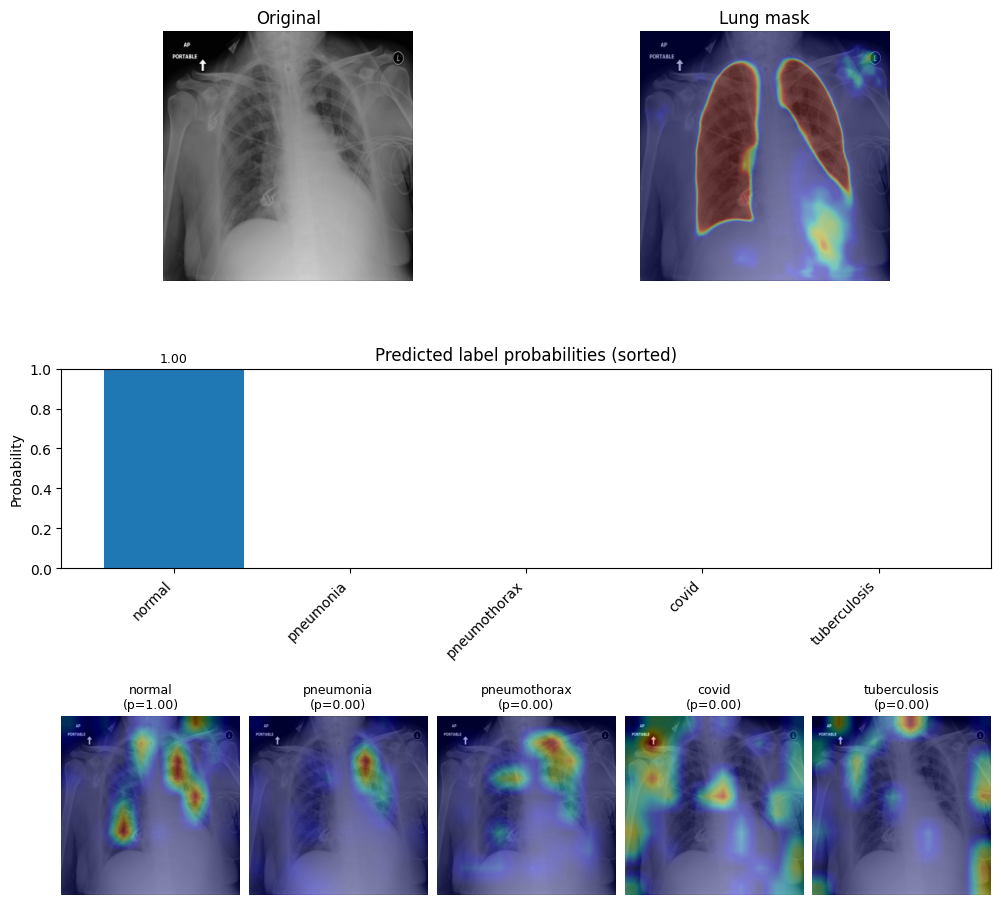

(array([9.9795234e-01, 1.5494152e-07, 1.6805870e-03, 3.6668294e-04,
        9.0994689e-08], dtype=float32),
 array([[[0.25789946, 0.25789946, 0.25789946, ..., 0.0410477 ,
          0.0410477 , 0.0410477 ],
         [0.25789946, 0.25789946, 0.25789946, ..., 0.0410477 ,
          0.0410477 , 0.0410477 ],
         [0.25789946, 0.25789946, 0.25789946, ..., 0.0410477 ,
          0.0410477 , 0.0410477 ],
         ...,
         [0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         [0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         [0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ]],
 
        [[0.04552557, 0.04552557, 0.04552557, ..., 0.2229245 ,
          0.2229245 , 0.2229245 ],
         [0.04552557, 0.04552557, 0.04552557, ..., 0.2229245 ,
          0.2229245 , 0.2229245 ],
         [0.04552557, 0.04552557, 0.04552557, ..., 0.2229245 ,
          0.2229245 , 0.2229

In [ ]:
predict_image("chexray/normal/image/0a5b4860-e6ab-4737-a389-9d0cf7300770.png")

Loading model with warm-up...
Loading checkpoint...
Model loaded successfully!
Warming up model...
Warm-up successful! Output keys: dict_keys(['logits', 'heatmaps', 'organs', 'heatmaps_logits'])
Model warm-up complete!
Starting evaluation on validation dataset...
Total batches: 106
Processed 10/106 batches...
Processed 20/106 batches...
Processed 30/106 batches...
Processed 40/106 batches...
Processed 50/106 batches...
Processed 60/106 batches...
Processed 70/106 batches...
Processed 80/106 batches...
Processed 90/106 batches...
Processed 100/106 batches...
Evaluation complete! Processed 1689 samples.
Data shapes:
  y_true_list: 1689
  y_pred_probs_list: 1689
  organ_preds_list: 1689
  heatmap_preds_list: 1689
  lung_mask_list: 1673
  lesion_mask_list: 1529
Final array shapes:
  y_true: (1689,)
  y_pred_probs: (1689, 5)
  organ_preds: (1689, 3, 320, 320)
  heatmap_preds: (1689, 5, 320, 320)
  lung_masks: (1673, 1, 320, 320)
  lesion_masks: (1529, 1, 320, 320)
Evaluation on 1689 validat

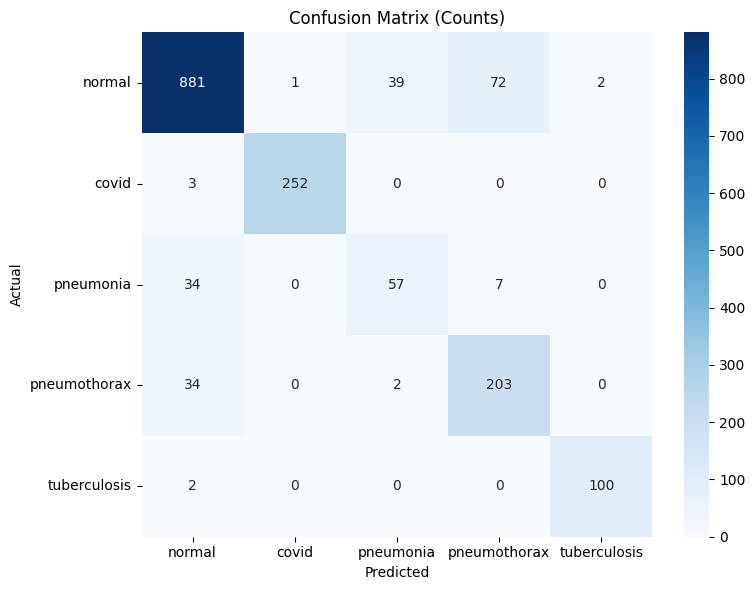

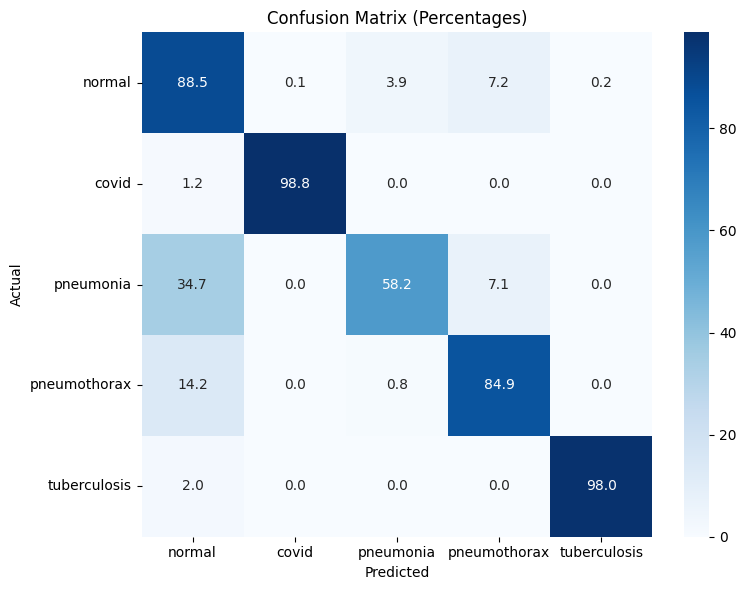

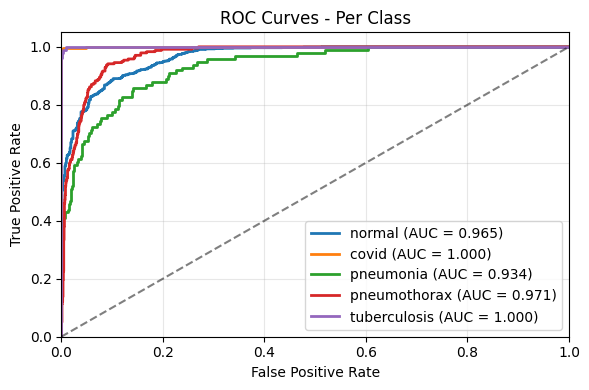

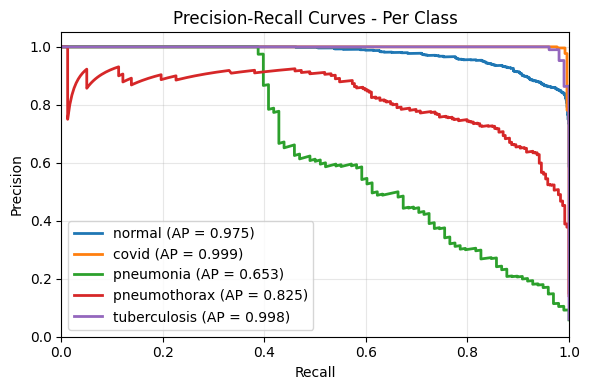

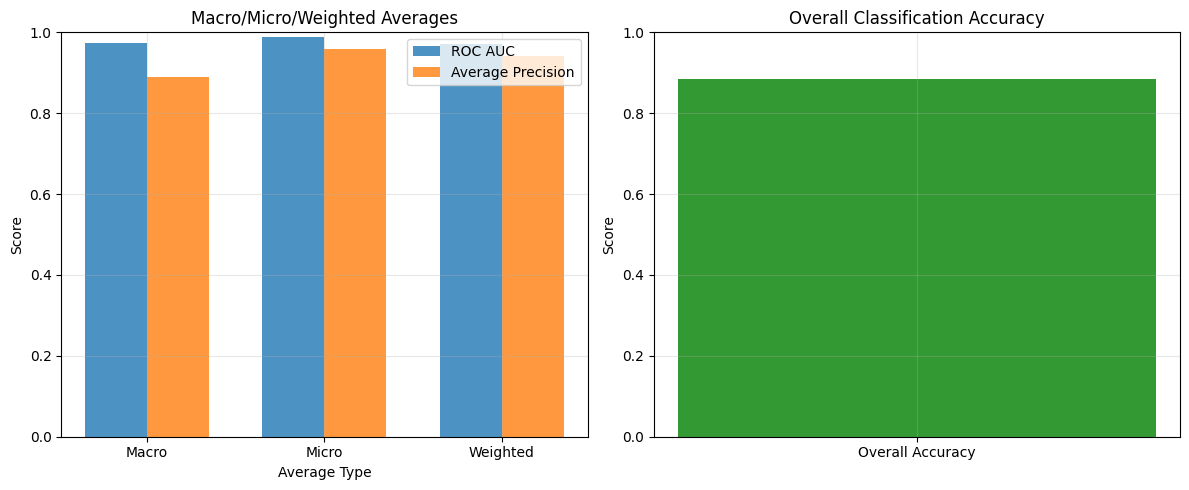

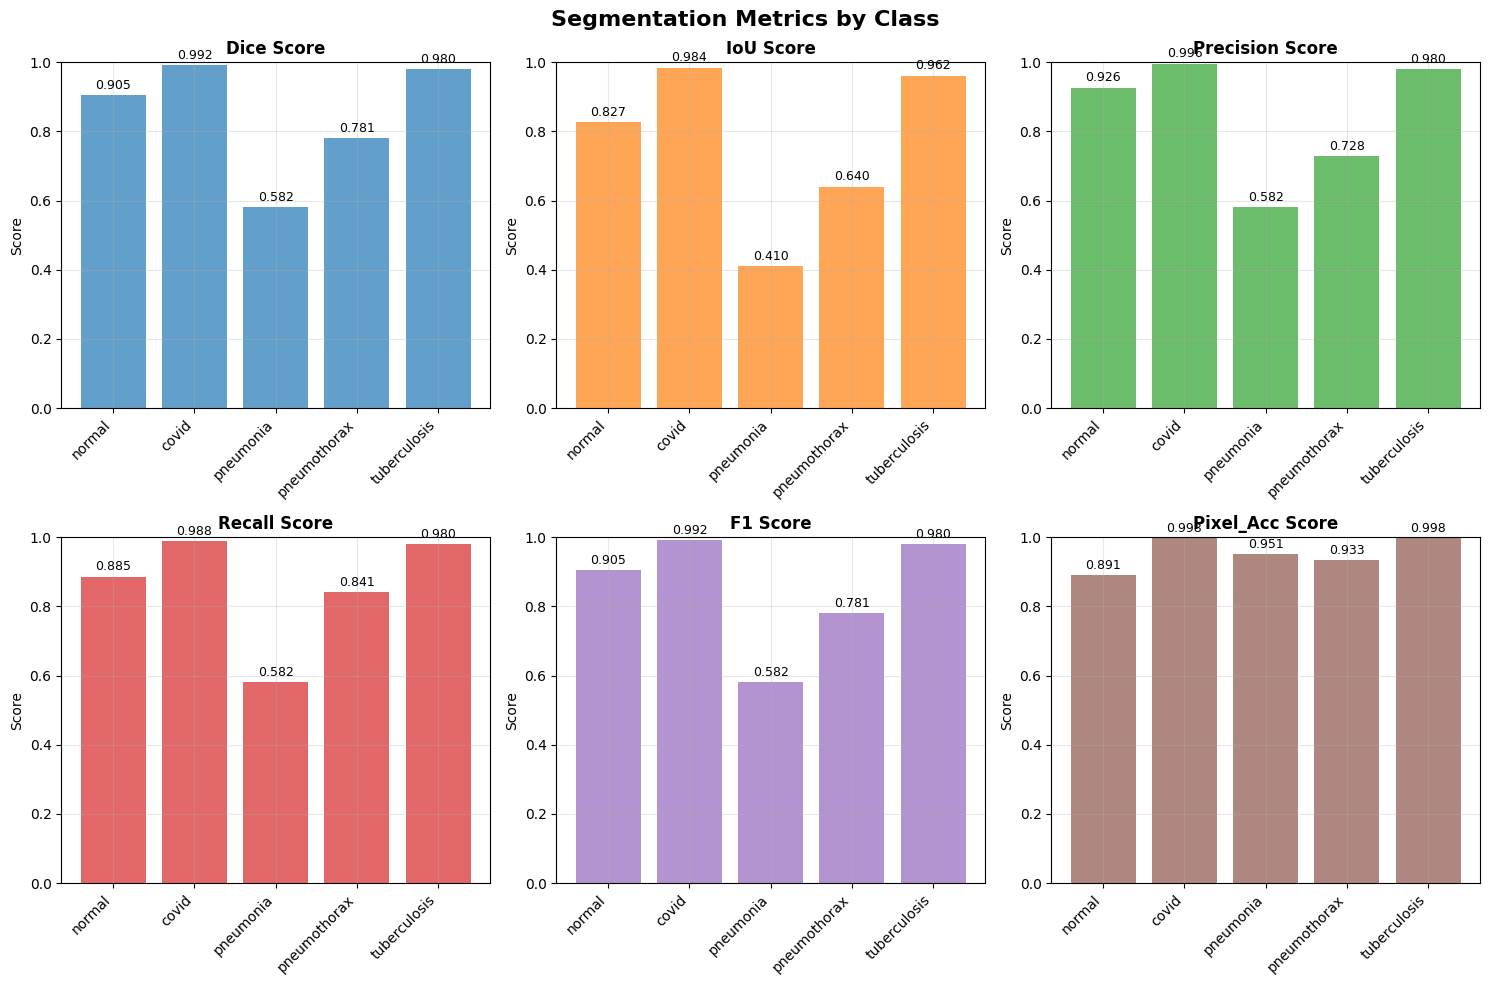


ORGAN SEGMENTATION METRICS
Lung Segmentation Metrics:
  Dice Score:     0.9113
  IoU:            0.8370
  Precision:      0.9126
  Recall:         0.9099
  F1-Score:       0.9113
  Pixel Accuracy: 0.9554
  Total Pixels:   42188800
  Positive Pixels: 10623214
  Samples with masks: 412

HEATMAP SEGMENTATION METRICS (PNEUMOTHORAX)
Pneumothorax Heatmap Segmentation Metrics:
  Dice Score:     0.0977
  IoU:            0.0513
  Precision:      0.1728
  Recall:         0.0681
  F1-Score:       0.0977
  Pixel Accuracy: 0.9819
  Total Pixels:   24473600
  Positive Pixels: 352760
  Samples with masks: 239


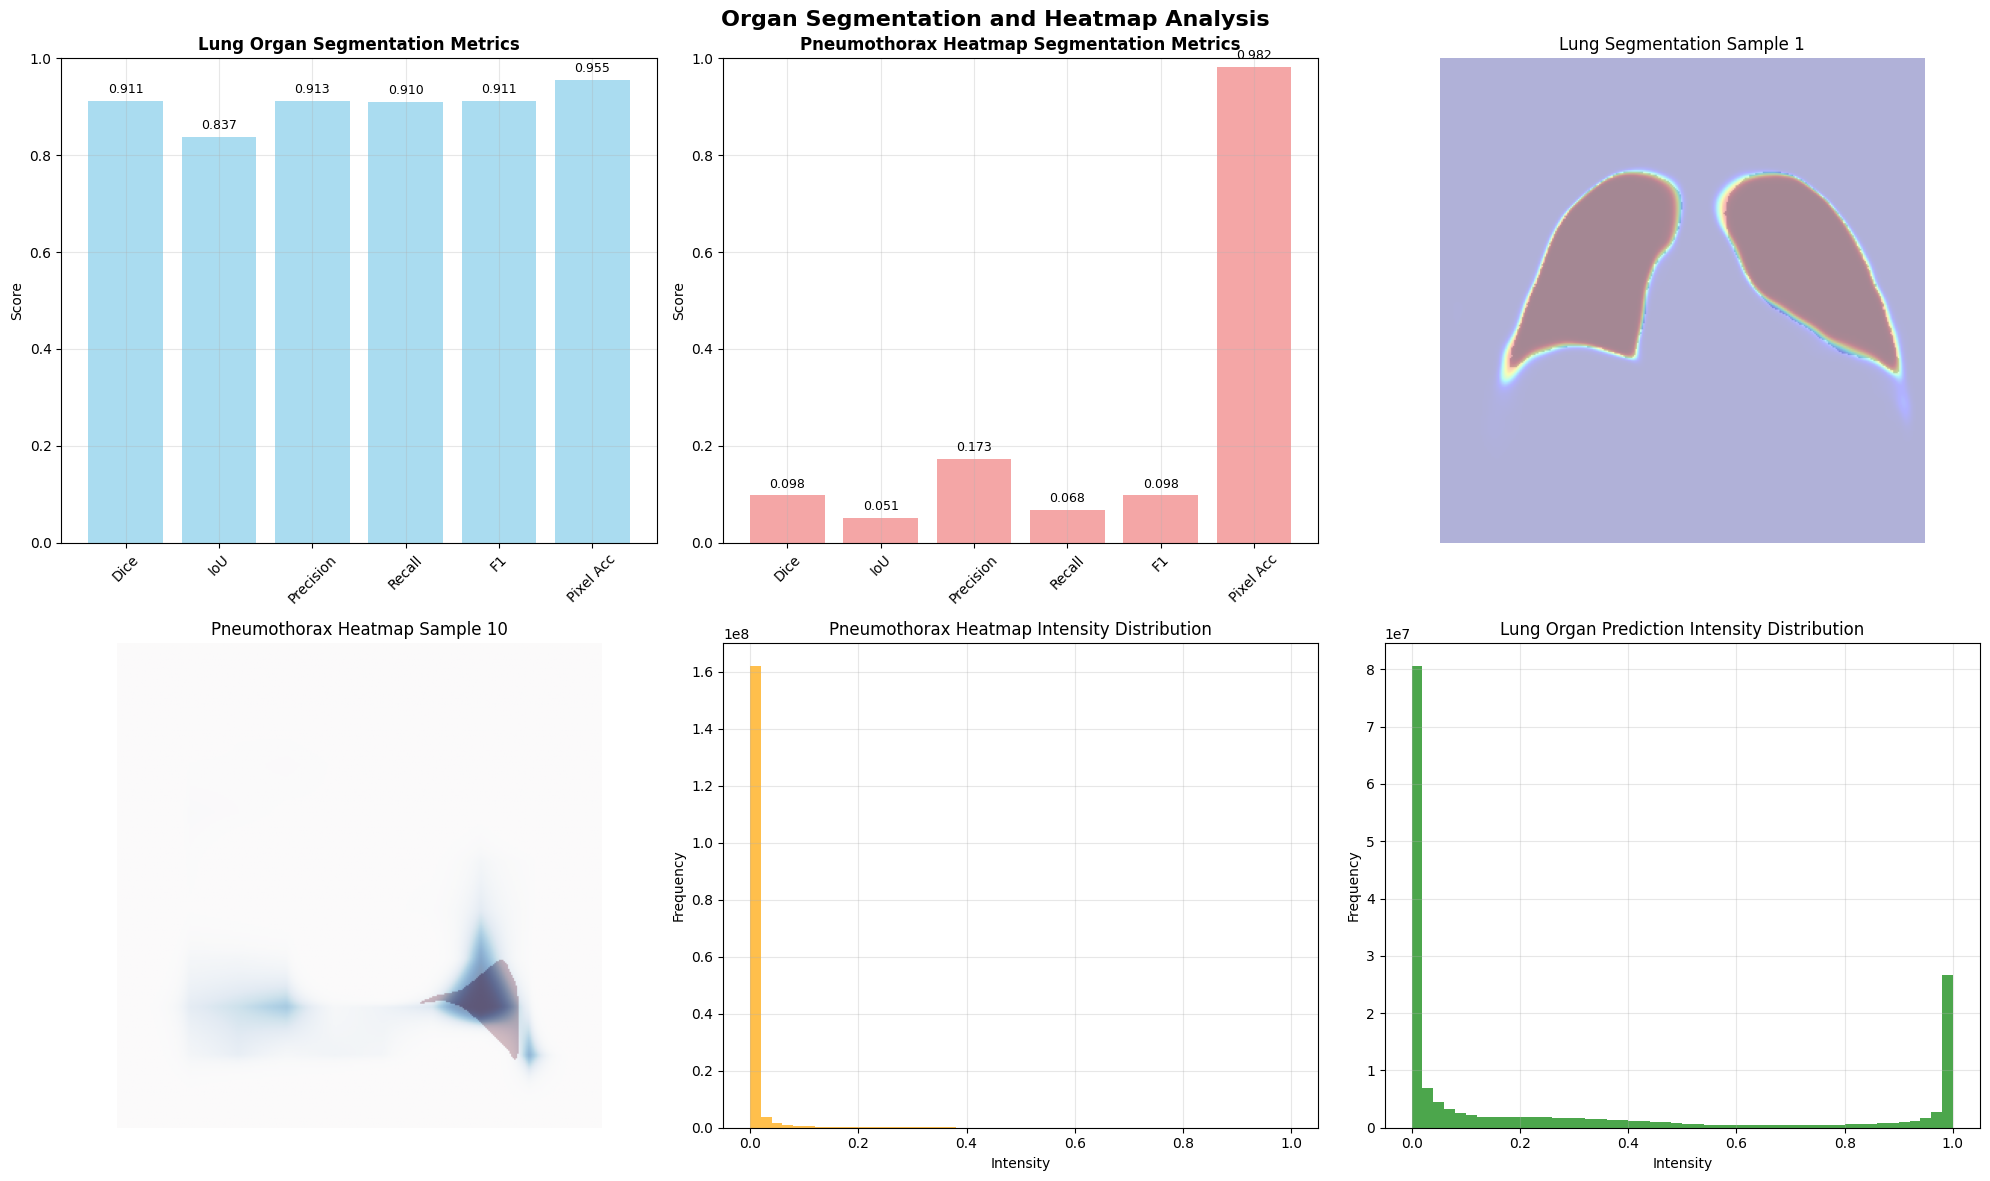


SAMPLE IMAGES VISUALIZATION


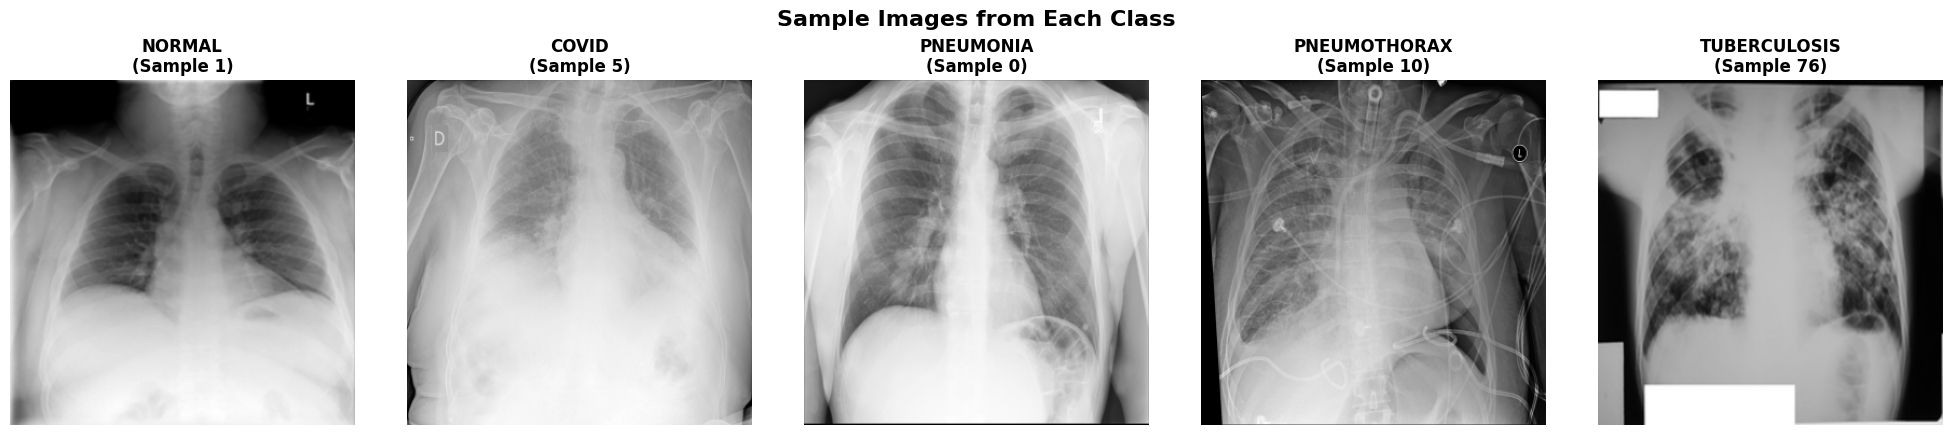

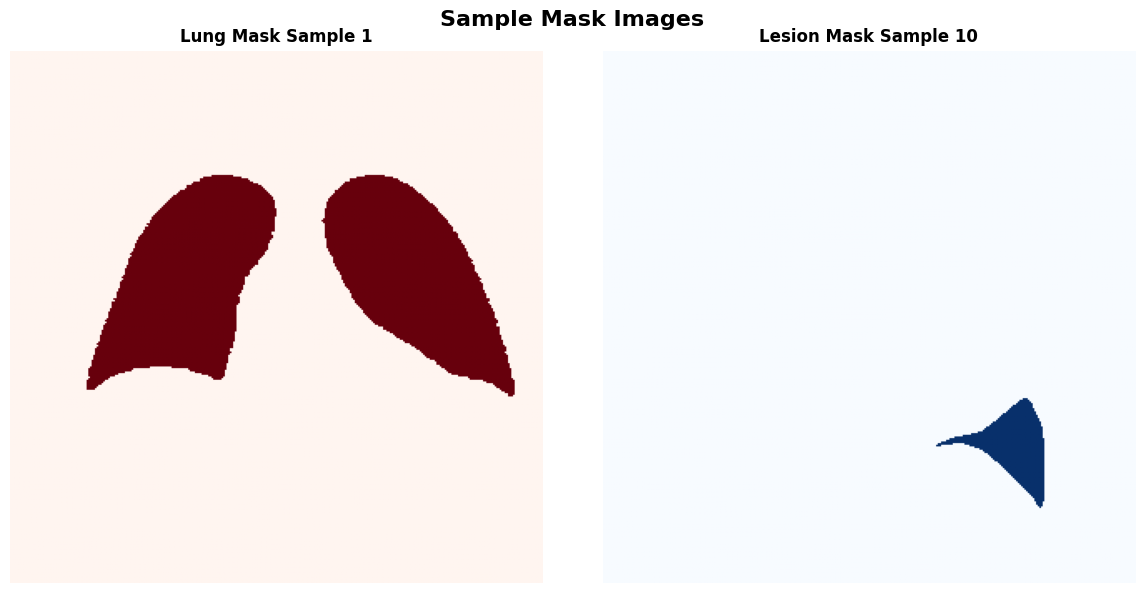

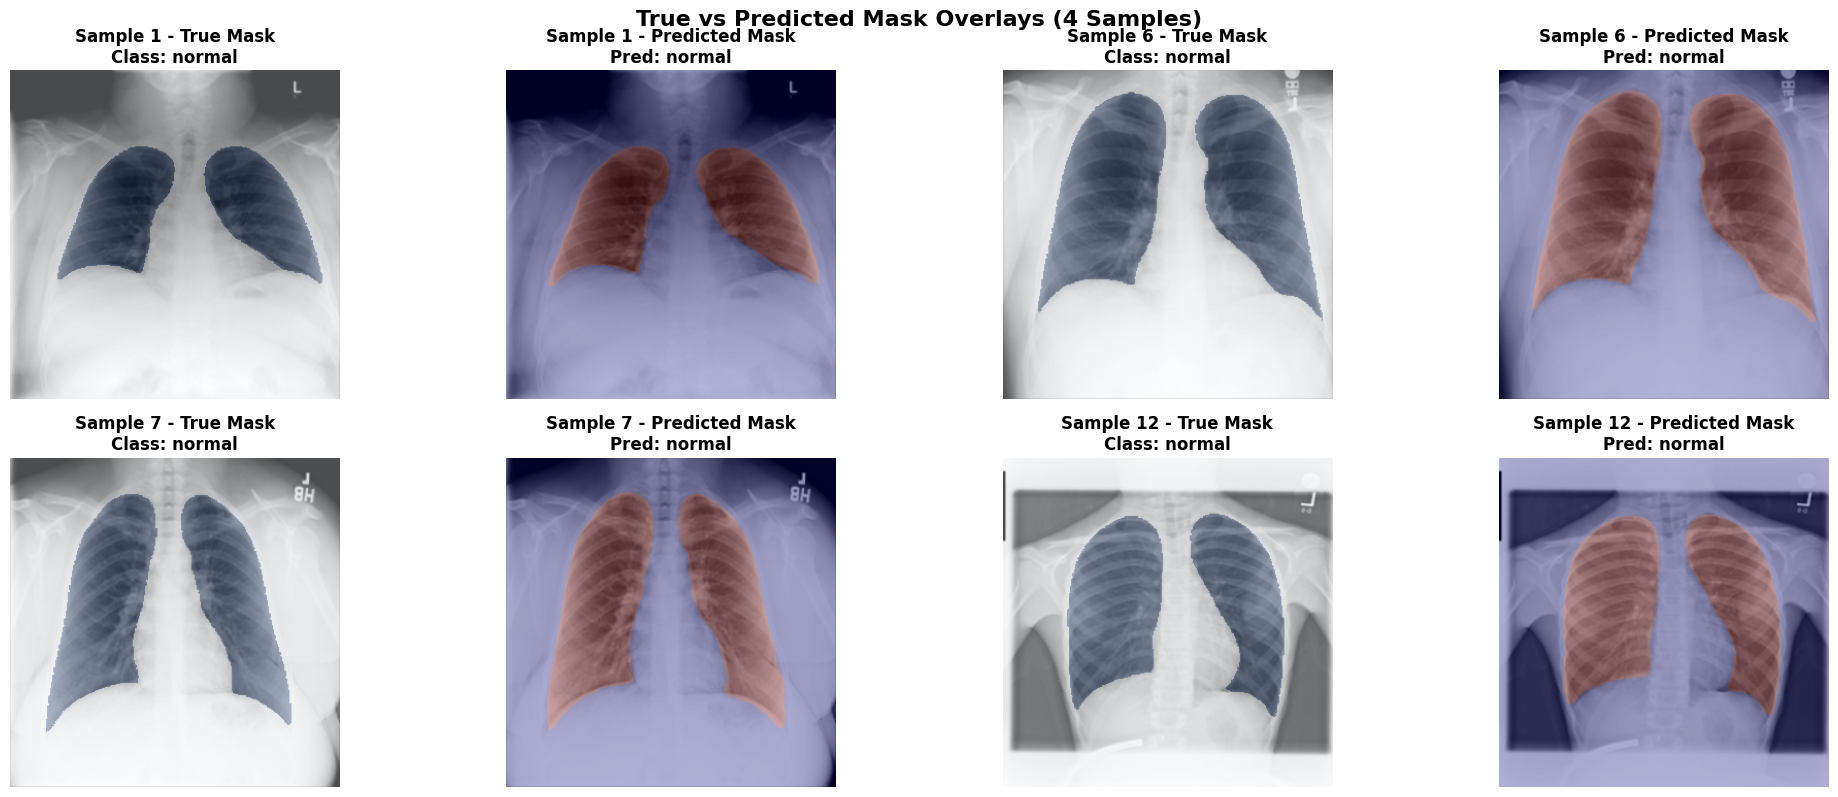


RANDOM SAMPLE VISUALIZATION


NameError: name 'show_images_with_masks' is not defined

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, accuracy_score, recall_score, f1_score, confusion_matrix

def plot_model_metrics(y_true, y_pred_probs, threshold=0.5, class_names=None):
    """
    Plots ROC, PR curves and prints useful metrics for a multi-class or binary classifier.
    y_true: np.array, shape (n_samples,) or (n_samples, n_classes)
    y_pred_probs: np.array, shape (n_samples,) or (n_samples, n_classes)
    threshold: float, threshold for binarizing probabilities
    class_names: list of str, optional
    """
    import numpy as np

    # If binary, reshape to (n_samples, 1)
    if y_pred_probs.ndim == 1 or (y_pred_probs.ndim == 2 and y_pred_probs.shape[1] == 1):
        y_pred_probs = np.array(y_pred_probs).reshape(-1, 1)
        y_true = np.array(y_true).reshape(-1, 1)
        n_classes = 1
    else:
        n_classes = y_pred_probs.shape[1]
        y_true = np.array(y_true)
        y_pred_probs = np.array(y_pred_probs)

    if class_names is None:
        class_names = [f"Class {i}" for i in range(n_classes)]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    # ROC and PR curves
    for i in range(n_classes):
        if n_classes == 1:
            y_true_bin = y_true.ravel()
            y_score = y_pred_probs.ravel()
        else:
            y_true_bin = y_true[:, i]
            y_score = y_pred_probs[:, i]

        # ROC
        fpr, tpr, _ = roc_curve(y_true_bin, y_score)
        roc_auc = auc(fpr, tpr)
        axes[0].plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.2f})")
        # PR
        precision, recall, _ = precision_recall_curve(y_true_bin, y_score)
        pr_auc = auc(recall, precision)
        axes[1].plot(recall, precision, label=f"{class_names[i]} (AUC={pr_auc:.2f})")

    axes[0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].set_title("ROC Curve")
    axes[0].legend()

    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_title("Precision-Recall Curve")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    # Compute and print metrics
    print("=== Metrics ===")
    for i in range(n_classes):
        if n_classes == 1:
            y_true_bin = y_true.ravel()
            y_score = y_pred_probs.ravel()
        else:
            y_true_bin = y_true[:, i]
            y_score = y_pred_probs[:, i]

        y_pred_bin = (y_score >= threshold).astype(int)

        acc = accuracy_score(y_true_bin, y_pred_bin)
        rec = recall_score(y_true_bin, y_pred_bin, zero_division=0)
        f1 = f1_score(y_true_bin, y_pred_bin, zero_division=0)
        # Dice = 2*TP/(2*TP+FP+FN) = 2*precision*recall/(precision+recall)
        precision_val = np.sum((y_pred_bin == 1) & (y_true_bin == 1)) / (np.sum(y_pred_bin == 1) + 1e-8)
        dice = 2 * precision_val * rec / (precision_val + rec + 1e-8)
        # AUC
        fpr, tpr, _ = roc_curve(y_true_bin, y_score)
        roc_auc = auc(fpr, tpr)
        precision_curve, recall_curve, _ = precision_recall_curve(y_true_bin, y_score)
        pr_auc = auc(recall_curve, precision_curve)

        print(f"\nClass: {class_names[i]}")
        print(f"  Accuracy: {acc:.3f}")
        print(f"  Recall:   {rec:.3f}")
        print(f"  F1:       {f1:.3f}")
        print(f"  Dice:     {dice:.3f}")
        print(f"  ROC AUC:  {roc_auc:.3f}")
        print(f"  PR  AUC:  {pr_auc:.3f}")
        cm = confusion_matrix(y_true_bin, y_pred_bin)
        print(f"  Confusion matrix:\n{cm}")



# Comprehensive Model Evaluation
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve, accuracy_score, 
    recall_score, f1_score, confusion_matrix, classification_report,
    precision_score, roc_auc_score, average_precision_score
)

# Get predictions from the validation dataset
print("Loading model with warm-up...")

# Check if checkpoint file exists
import os
checkpoint_path = "checkpoint_epoch_013.pt"
if not os.path.exists(checkpoint_path):
    print(f"ERROR: Checkpoint file {checkpoint_path} not found!")
    print("Available checkpoint files:")
    import glob
    for f in glob.glob("checkpoint_epoch_*.pt"):
        print(f"  {f}")
    raise FileNotFoundError(f"Checkpoint {checkpoint_path} not found")

try:
    # Load model with proper torch.load settings for checkpoint files
    model = StudentMultiTask(num_classes=NUM_CLASSES, out_size=IMG_SIZE).to(device)
    
    # Warm-up to initialize lazy modules
    with torch.no_grad():
        _ = model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=device))
    
    # Load checkpoint with weights_only=False to handle numpy objects
    print("Loading checkpoint...")
    state = torch.load(checkpoint_path, map_location=device, weights_only=False)
    
    # Extract model state dict
    if isinstance(state, dict) and "model" in state:
        state = state["model"]
    elif isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    
    # Load state dict
    model.load_state_dict(state, strict=False)
    model.eval()
    print("Model loaded successfully!")
    
except Exception as e:
    print(f"Error loading model: {e}")
    raise

# Ensure model is properly warmed up
print("Warming up model...")
try:
    with torch.no_grad():
        dummy_input = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=device)
        dummy_output = model(dummy_input)
        print(f"Warm-up successful! Output keys: {dummy_output.keys()}")
except Exception as e:
    print(f"Error during warm-up: {e}")
    raise
print("Model warm-up complete!")
y_true_list = []
y_pred_probs_list = []
organ_preds_list = []
heatmap_preds_list = []
lung_mask_list = []
lesion_mask_list = []

print(f"Starting evaluation on validation dataset...")
print(f"Total batches: {len(test_dl)}")

with torch.no_grad():
    for batch_idx, batch in enumerate(test_dl):
        if batch is None:
            print(f"Batch {batch_idx} is None, skipping...")
            continue
            
        try:
            xb = batch["image"].to(device)
            yb = batch["label"].to(device)
            lung_mask = batch.get("lung_mask", None)
            lesion_mask = batch.get("lesion_mask", None)
            
            out = model(xb)
            probs = torch.softmax(out["logits"], dim=1)
            organs = torch.sigmoid(out["organs"])  # organ predictions
            heatmaps = out["heatmaps"]  # heatmap predictions
            
            y_true_list.extend(yb.cpu().numpy())
            y_pred_probs_list.extend(probs.cpu().numpy())
            organ_preds_list.extend(organs.cpu().numpy())
            heatmap_preds_list.extend(heatmaps.cpu().numpy())
            
            if lung_mask is not None:
                lung_mask_list.extend(lung_mask.cpu().numpy())
            if lesion_mask is not None:
                lesion_mask_list.extend(lesion_mask.cpu().numpy())
                
            # Progress indicator
            if (batch_idx + 1) % 10 == 0:
                print(f"Processed {batch_idx + 1}/{len(test_dl)} batches...")
                
        except Exception as e:
            print(f"Error processing batch {batch_idx}: {e}")
            continue

print(f"Evaluation complete! Processed {len(y_true_list)} samples.")

# Validate data before processing
if len(y_true_list) == 0:
    raise ValueError("No data collected from validation dataset!")

print(f"Data shapes:")
print(f"  y_true_list: {len(y_true_list)}")
print(f"  y_pred_probs_list: {len(y_pred_probs_list)}")
print(f"  organ_preds_list: {len(organ_preds_list)}")
print(f"  heatmap_preds_list: {len(heatmap_preds_list)}")
print(f"  lung_mask_list: {len(lung_mask_list)}")
print(f"  lesion_mask_list: {len(lesion_mask_list)}")

y_true = np.array(y_true_list)  # shape: (n_samples,)
y_pred_probs = np.array(y_pred_probs_list)  # shape: (n_samples, n_classes)
y_pred = np.argmax(y_pred_probs, axis=1)  # predicted class indices

# Organ and heatmap predictions
organ_preds = np.array(organ_preds_list)  # shape: (n_samples, 3, H, W) - [bg, lung, heart]
heatmap_preds = np.array(heatmap_preds_list)  # shape: (n_samples, n_classes, H, W)
lung_masks = np.array(lung_mask_list) if lung_mask_list else None  # shape: (n_samples, 1, H, W)
lesion_masks = np.array(lesion_mask_list) if lesion_mask_list else None  # shape: (n_samples, 1, H, W)

print(f"Final array shapes:")
print(f"  y_true: {y_true.shape}")
print(f"  y_pred_probs: {y_pred_probs.shape}")
print(f"  organ_preds: {organ_preds.shape}")
print(f"  heatmap_preds: {heatmap_preds.shape}")
if lung_masks is not None:
    print(f"  lung_masks: {lung_masks.shape}")
if lesion_masks is not None:
    print(f"  lesion_masks: {lesion_masks.shape}")

# Convert y_true to one-hot encoding for multi-class metrics
y_true_onehot = np.eye(len(CLASS_NAMES))[y_true]  # shape: (n_samples, n_classes)

print(f"Evaluation on {len(y_true)} validation samples")
print(f"Classes: {CLASS_NAMES}")
print(f"Class distribution: {np.bincount(y_true)}")

# 1. Confusion Matrix (Counts)
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Confusion Matrix (Counts)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# 1b. Confusion Matrix (Percentages)
plt.figure(figsize=(8, 6))
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
sns.heatmap(cm_percent, annot=True, fmt='.1f', cmap='Blues', 
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Confusion Matrix (Percentages)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# 2. ROC Curves (separate plot for each class)
plt.figure(figsize=(6, 4))
for i, class_name in enumerate(CLASS_NAMES):
    y_true_bin = y_true_onehot[:, i]
    y_score = y_pred_probs[:, i]
    
    fpr, tpr, _ = roc_curve(y_true_bin, y_score)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, label=f'{class_name} (AUC = {roc_auc:.3f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Per Class')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Precision-Recall Curves (separate plot for each class)
plt.figure(figsize=(6, 4))
for i, class_name in enumerate(CLASS_NAMES):
    y_true_bin = y_true_onehot[:, i]
    y_score = y_pred_probs[:, i]
    
    precision, recall, _ = precision_recall_curve(y_true_bin, y_score)
    pr_auc = auc(recall, precision)
    
    plt.plot(recall, precision, label=f'{class_name} (AP = {pr_auc:.3f})', linewidth=2)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves - Per Class')
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Macro and Micro averages
plt.figure(figsize=(12, 5))

# Macro averages
macro_auc = roc_auc_score(y_true_onehot, y_pred_probs, average='macro')
macro_ap = average_precision_score(y_true_onehot, y_pred_probs, average='macro')

# Micro averages
micro_auc = roc_auc_score(y_true_onehot, y_pred_probs, average='micro')
micro_ap = average_precision_score(y_true_onehot, y_pred_probs, average='micro')

# Weighted averages
weighted_auc = roc_auc_score(y_true_onehot, y_pred_probs, average='weighted')
weighted_ap = average_precision_score(y_true_onehot, y_pred_probs, average='weighted')

metrics = ['Macro', 'Micro', 'Weighted']
auc_scores = [macro_auc, micro_auc, weighted_auc]
ap_scores = [macro_ap, micro_ap, weighted_ap]

x = np.arange(len(metrics))
width = 0.35

plt.subplot(1, 2, 1)
plt.bar(x - width/2, auc_scores, width, label='ROC AUC', alpha=0.8)
plt.bar(x + width/2, ap_scores, width, label='Average Precision', alpha=0.8)
plt.xlabel('Average Type')
plt.ylabel('Score')
plt.title('Macro/Micro/Weighted Averages')
plt.xticks(x, metrics)
plt.legend()
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)

# Overall accuracy
accuracy = accuracy_score(y_true, y_pred)
plt.subplot(1, 2, 2)
plt.bar(['Overall Accuracy'], [accuracy], alpha=0.8, color='green')
plt.ylabel('Score')
plt.title('Overall Classification Accuracy')
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5. Segmentation Metrics Plot (Dice, IoU, Precision, Recall, F1, Pixel Acc)
plt.figure(figsize=(15, 10))

# Calculate segmentation metrics for each class
segmentation_metrics = {
    'Dice': [],
    'IoU': [],
    'Precision': [],
    'Recall': [],
    'F1': [],
    'Pixel_Acc': []
}

for i, class_name in enumerate(CLASS_NAMES):
    y_true_bin = y_true_onehot[:, i]
    y_score = y_pred_probs[:, i]
    y_pred_bin = (y_score >= 0.5).astype(int)
    
    # Basic metrics
    precision = precision_score(y_true_bin, y_pred_bin, zero_division=0)
    recall = recall_score(y_true_bin, y_pred_bin, zero_division=0)
    f1 = f1_score(y_true_bin, y_pred_bin, zero_division=0)
    
    # Dice coefficient (2 * precision * recall / (precision + recall))
    dice = 2 * precision * recall / (precision + recall + 1e-8) if (precision + recall) > 0 else 0
    
    # IoU (Intersection over Union) = TP / (TP + FP + FN)
    tp = np.sum((y_true_bin == 1) & (y_pred_bin == 1))
    fp = np.sum((y_true_bin == 0) & (y_pred_bin == 1))
    fn = np.sum((y_true_bin == 1) & (y_pred_bin == 0))
    iou = tp / (tp + fp + fn + 1e-8)
    
    # Pixel Accuracy = (TP + TN) / (TP + TN + FP + FN)
    tn = np.sum((y_true_bin == 0) & (y_pred_bin == 0))
    pixel_acc = (tp + tn) / (tp + tn + fp + fn + 1e-8)
    
    segmentation_metrics['Dice'].append(dice)
    segmentation_metrics['IoU'].append(iou)
    segmentation_metrics['Precision'].append(precision)
    segmentation_metrics['Recall'].append(recall)
    segmentation_metrics['F1'].append(f1)
    segmentation_metrics['Pixel_Acc'].append(pixel_acc)

# Create subplots for each metric
metrics_to_plot = ['Dice', 'IoU', 'Precision', 'Recall', 'F1', 'Pixel_Acc']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

for idx, metric in enumerate(metrics_to_plot):
    plt.subplot(2, 3, idx + 1)
    bars = plt.bar(CLASS_NAMES, segmentation_metrics[metric], color=colors[idx], alpha=0.7)
    plt.title(f'{metric} Score', fontsize=12, fontweight='bold')
    plt.ylabel('Score')
    plt.ylim(0, 1)
    plt.xticks(rotation=45, ha='right')
    plt.grid(True, alpha=0.3)
    
    # Add value labels on bars
    for bar, value in zip(bars, segmentation_metrics[metric]):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'{value:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Segmentation Metrics by Class', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 6. Organ Segmentation Metrics
if lung_masks is not None and len(lung_masks) > 0:
    print("\n" + "="*80)
    print("ORGAN SEGMENTATION METRICS")
    print("="*80)
    
    # Calculate organ segmentation metrics - process sample by sample to avoid memory issues
    lung_preds = organ_preds[:, 1, :, :]  # lung channel (index 1)
    lung_gt = lung_masks[:, 0, :, :]  # ground truth lung masks
    
    # Initialize accumulators
    total_tp = total_fp = total_fn = total_tn = 0
    total_pixels = 0
    total_positive_pixels = 0
    
    # Process each sample individually
    for i in range(len(lung_masks)):
        if np.sum(lung_gt[i]) > 0:  # Only process samples with ground truth masks
            # Get predictions and ground truth for this sample
            pred_sample = lung_preds[i]
            gt_sample = lung_gt[i]
            
            # Binarize predictions
            pred_bin = (pred_sample >= 0.5).astype(int)
            gt_bin = (gt_sample >= 0.5).astype(int)
            
            # Calculate confusion matrix for this sample
            tp = np.sum((gt_bin == 1) & (pred_bin == 1))
            fp = np.sum((gt_bin == 0) & (pred_bin == 1))
            fn = np.sum((gt_bin == 1) & (pred_bin == 0))
            tn = np.sum((gt_bin == 0) & (pred_bin == 0))
            
            # Accumulate
            total_tp += tp
            total_fp += fp
            total_fn += fn
            total_tn += tn
            total_pixels += gt_bin.size
            total_positive_pixels += np.sum(gt_bin)
    
    # Calculate final metrics
    lung_precision = total_tp / (total_tp + total_fp + 1e-8)
    lung_recall = total_tp / (total_tp + total_fn + 1e-8)
    lung_f1 = 2 * lung_precision * lung_recall / (lung_precision + lung_recall + 1e-8)
    lung_dice = lung_f1  # Dice = F1 for binary segmentation
    lung_iou = total_tp / (total_tp + total_fp + total_fn + 1e-8)
    lung_pixel_acc = (total_tp + total_tn) / (total_tp + total_tn + total_fp + total_fn + 1e-8)
    
    print(f"Lung Segmentation Metrics:")
    print(f"  Dice Score:     {lung_dice:.4f}")
    print(f"  IoU:            {lung_iou:.4f}")
    print(f"  Precision:      {lung_precision:.4f}")
    print(f"  Recall:         {lung_recall:.4f}")
    print(f"  F1-Score:       {lung_f1:.4f}")
    print(f"  Pixel Accuracy: {lung_pixel_acc:.4f}")
    print(f"  Total Pixels:   {total_pixels}")
    print(f"  Positive Pixels: {total_positive_pixels}")
    print(f"  Samples with masks: {np.sum([np.sum(lung_gt[i]) > 0 for i in range(len(lung_gt))])}")

# 7. Heatmap Segmentation Metrics (for pneumothorax)
if lesion_masks is not None and len(lesion_masks) > 0 and PNX_INDEX is not None:
    print("\n" + "="*80)
    print("HEATMAP SEGMENTATION METRICS (PNEUMOTHORAX)")
    print("="*80)
    
    # Get pneumothorax heatmap predictions
    pnx_heatmap_preds = heatmap_preds[:, PNX_INDEX, :, :]  # pneumothorax heatmap
    pnx_lesion_gt = lesion_masks[:, 0, :, :]  # ground truth lesion masks
    
    # Initialize accumulators
    total_tp = total_fp = total_fn = total_tn = 0
    total_pixels = 0
    total_positive_pixels = 0
    
    # Process each sample individually
    for i in range(len(lesion_masks)):
        if np.sum(pnx_lesion_gt[i]) > 0:  # Only process samples with ground truth masks
            # Get predictions and ground truth for this sample
            pred_sample = pnx_heatmap_preds[i]
            gt_sample = pnx_lesion_gt[i]
            
            # Binarize predictions
            pred_bin = (pred_sample >= 0.5).astype(int)
            gt_bin = (gt_sample >= 0.5).astype(int)
            
            # Calculate confusion matrix for this sample
            tp = np.sum((gt_bin == 1) & (pred_bin == 1))
            fp = np.sum((gt_bin == 0) & (pred_bin == 1))
            fn = np.sum((gt_bin == 1) & (pred_bin == 0))
            tn = np.sum((gt_bin == 0) & (pred_bin == 0))
            
            # Accumulate
            total_tp += tp
            total_fp += fp
            total_fn += fn
            total_tn += tn
            total_pixels += gt_bin.size
            total_positive_pixels += np.sum(gt_bin)
    
    # Calculate final metrics
    pnx_precision = total_tp / (total_tp + total_fp + 1e-8)
    pnx_recall = total_tp / (total_tp + total_fn + 1e-8)
    pnx_f1 = 2 * pnx_precision * pnx_recall / (pnx_precision + pnx_recall + 1e-8)
    pnx_dice = pnx_f1  # Dice = F1 for binary segmentation
    pnx_iou = total_tp / (total_tp + total_fp + total_fn + 1e-8)
    pnx_pixel_acc = (total_tp + total_tn) / (total_tp + total_tn + total_fp + total_fn + 1e-8)
    
    print(f"Pneumothorax Heatmap Segmentation Metrics:")
    print(f"  Dice Score:     {pnx_dice:.4f}")
    print(f"  IoU:            {pnx_iou:.4f}")
    print(f"  Precision:      {pnx_precision:.4f}")
    print(f"  Recall:         {pnx_recall:.4f}")
    print(f"  F1-Score:       {pnx_f1:.4f}")
    print(f"  Pixel Accuracy: {pnx_pixel_acc:.4f}")
    print(f"  Total Pixels:   {total_pixels}")
    print(f"  Positive Pixels: {total_positive_pixels}")
    print(f"  Samples with masks: {np.sum([np.sum(pnx_lesion_gt[i]) > 0 for i in range(len(pnx_lesion_gt))])}")

# 8. Organ and Heatmap Visualization
plt.figure(figsize=(20, 12))

# Organ segmentation metrics bar chart
if lung_masks is not None and len(lung_masks) > 0:
    plt.subplot(2, 3, 1)
    organ_metrics = [lung_dice, lung_iou, lung_precision, lung_recall, lung_f1, lung_pixel_acc]
    organ_metric_names = ['Dice', 'IoU', 'Precision', 'Recall', 'F1', 'Pixel Acc']
    bars = plt.bar(organ_metric_names, organ_metrics, color='skyblue', alpha=0.7)
    plt.title('Lung Organ Segmentation Metrics', fontweight='bold')
    plt.ylabel('Score')
    plt.ylim(0, 1)
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    
    # Add value labels
    for bar, value in zip(bars, organ_metrics):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'{value:.3f}', ha='center', va='bottom', fontsize=9)

# Heatmap segmentation metrics bar chart
if lesion_masks is not None and len(lesion_masks) > 0 and PNX_INDEX is not None:
    plt.subplot(2, 3, 2)
    heatmap_metrics = [pnx_dice, pnx_iou, pnx_precision, pnx_recall, pnx_f1, pnx_pixel_acc]
    heatmap_metric_names = ['Dice', 'IoU', 'Precision', 'Recall', 'F1', 'Pixel Acc']
    bars = plt.bar(heatmap_metric_names, heatmap_metrics, color='lightcoral', alpha=0.7)
    plt.title('Pneumothorax Heatmap Segmentation Metrics', fontweight='bold')
    plt.ylabel('Score')
    plt.ylim(0, 1)
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    
    # Add value labels
    for bar, value in zip(bars, heatmap_metrics):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'{value:.3f}', ha='center', va='bottom', fontsize=9)

# Sample organ predictions visualization
if lung_masks is not None and len(lung_masks) > 0:
    # Find a sample with lung mask
    sample_idx = 0
    for i in range(len(lung_masks)):
        if np.sum(lung_masks[i]) > 0:
            sample_idx = i
            break
    
    plt.subplot(2, 3, 3)
    lung_pred_sample = lung_preds[sample_idx]
    lung_gt_sample = lung_masks[sample_idx, 0]
    
    # Create overlay visualization
    plt.imshow(lung_gt_sample, cmap='Blues', alpha=0.3, label='Ground Truth')
    plt.imshow(lung_pred_sample, cmap='jet', alpha=0.3, label='Prediction')
    plt.title(f'Lung Segmentation Sample {sample_idx}')
    plt.axis('off')

# Sample heatmap predictions visualization
if lesion_masks is not None and len(lesion_masks) > 0 and PNX_INDEX is not None:
    # Find a sample with lesion mask
    sample_idx = 0
    for i in range(len(lesion_masks)):
        if np.sum(lesion_masks[i]) > 0:
            sample_idx = i
            break
    
    plt.subplot(2, 3, 4)
    pnx_pred_sample = pnx_heatmap_preds[sample_idx]
    pnx_gt_sample = lesion_masks[sample_idx, 0]
    
    # Create overlay visualization
    plt.imshow(pnx_gt_sample, cmap='Reds', alpha=0.5, label='Ground Truth')
    plt.imshow(pnx_pred_sample, cmap='Blues', alpha=0.5, label='Prediction')
    plt.title(f'Pneumothorax Heatmap Sample {sample_idx}')
    plt.axis('off')

# Heatmap intensity distribution
plt.subplot(2, 3, 5)
if lesion_masks is not None and len(lesion_masks) > 0 and PNX_INDEX is not None:
    pnx_heatmap_flat = pnx_heatmap_preds.flatten()
    plt.hist(pnx_heatmap_flat, bins=50, alpha=0.7, color='orange')
    plt.title('Pneumothorax Heatmap Intensity Distribution')
    plt.xlabel('Intensity')
    plt.ylabel('Frequency')
    plt.grid(True, alpha=0.3)

# Organ prediction intensity distribution
plt.subplot(2, 3, 6)
if lung_masks is not None and len(lung_masks) > 0:
    lung_pred_flat = lung_preds.flatten()
    plt.hist(lung_pred_flat, bins=50, alpha=0.7, color='green')
    plt.title('Lung Organ Prediction Intensity Distribution')
    plt.xlabel('Intensity')
    plt.ylabel('Frequency')
    plt.grid(True, alpha=0.3)

plt.suptitle('Organ Segmentation and Heatmap Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 9. Sample Images Visualization
print("\n" + "="*80)
print("SAMPLE IMAGES VISUALIZATION")
print("="*80)

# Find sample images from each class
sample_indices = {}
for class_idx, class_name in enumerate(CLASS_NAMES):
    # Find first sample of this class
    for i in range(len(y_true)):
        if y_true[i] == class_idx:
            sample_indices[class_name] = i
            break

# 1. Sample images from each class
plt.figure(figsize=(20, 8))
for idx, (class_name, sample_idx) in enumerate(sample_indices.items()):
    plt.subplot(2, 5, idx + 1)
    
    # Get the original image from the validation dataset
    batch_idx = sample_idx // BATCH_SIZE
    item_idx = sample_idx % BATCH_SIZE
    
    # Get batch from dataloader
    val_batches = list(test_dl)
    if batch_idx < len(val_batches) and val_batches[batch_idx] is not None:
        batch = val_batches[batch_idx]
        if item_idx < len(batch["image"]):
            # Denormalize image for display
            img = batch["image"][item_idx].cpu().numpy()
            img = (img * 0.5 + 0.5)  # Denormalize from [-1,1] to [0,1]
            img = np.transpose(img, (1, 2, 0))  # CHW to HWC
            img = np.mean(img, axis=2)  # Convert to grayscale
            
            plt.imshow(img, cmap='gray')
            plt.title(f'{class_name.upper()}\n(Sample {sample_idx})', fontweight='bold')
            plt.axis('off')
        else:
            plt.text(0.5, 0.5, f'No image\nfor {class_name}', ha='center', va='center')
            plt.axis('off')
    else:
        plt.text(0.5, 0.5, f'No batch\nfor {class_name}', ha='center', va='center')
        plt.axis('off')

plt.suptitle('Sample Images from Each Class', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Sample mask images (lung and lesion masks)
plt.figure(figsize=(12, 6))

# Find samples with lung masks
lung_sample_idx = None
for i in range(len(lung_masks)) if lung_masks is not None else []:
    if np.sum(lung_masks[i]) > 0:
        lung_sample_idx = i
        break

# Find samples with lesion masks
lesion_sample_idx = None
for i in range(len(lesion_masks)) if lesion_masks is not None else []:
    if np.sum(lesion_masks[i]) > 0:
        lesion_sample_idx = i
        break

if lung_sample_idx is not None:
    plt.subplot(1, 2, 1)
    lung_mask_sample = lung_masks[lung_sample_idx, 0]
    plt.imshow(lung_mask_sample, cmap='Reds')
    plt.title(f'Lung Mask Sample {lung_sample_idx}', fontweight='bold')
    plt.axis('off')
else:
    plt.subplot(1, 2, 1)
    plt.text(0.5, 0.5, 'No lung masks\navailable', ha='center', va='center')
    plt.axis('off')

if lesion_sample_idx is not None:
    plt.subplot(1, 2, 2)
    lesion_mask_sample = lesion_masks[lesion_sample_idx, 0]
    plt.imshow(lesion_mask_sample, cmap='Blues')
    plt.title(f'Lesion Mask Sample {lesion_sample_idx}', fontweight='bold')
    plt.axis('off')
else:
    plt.subplot(1, 2, 2)
    plt.text(0.5, 0.5, 'No lesion masks\navailable', ha='center', va='center')
    plt.axis('off')

plt.suptitle('Sample Mask Images', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. True vs Predicted Mask Overlays
plt.figure(figsize=(20, 16))

# Select 4 samples with masks for comparison
samples_with_masks = []
for i in range(len(lung_masks)) if lung_masks is not None else []:
    if np.sum(lung_masks[i]) > 0:
        samples_with_masks.append(i)
        if len(samples_with_masks) >= 4:
            break

if len(samples_with_masks) < 4:
    # If not enough samples with lung masks, add any samples
    for i in range(len(y_true)):
        if i not in samples_with_masks:
            samples_with_masks.append(i)
            if len(samples_with_masks) >= 4:
                break

for plot_idx, sample_idx in enumerate(samples_with_masks[:4]):
    # Get original image
    batch_idx = sample_idx // BATCH_SIZE
    item_idx = sample_idx % BATCH_SIZE
    
    val_batches = list(test_dl)
    if batch_idx < len(val_batches) and val_batches[batch_idx] is not None:
        batch = val_batches[batch_idx]
        if item_idx < len(batch["image"]):
            # Denormalize image for display
            img = batch["image"][item_idx].cpu().numpy()
            img = (img * 0.5 + 0.5)  # Denormalize from [-1,1] to [0,1]
            img = np.transpose(img, (1, 2, 0))  # CHW to HWC
            img = np.mean(img, axis=2)  # Convert to grayscale
            
            # True mask overlay
            plt.subplot(4, 4, plot_idx * 2 + 1)
            plt.imshow(img, cmap='gray')
            if lung_masks is not None and sample_idx < len(lung_masks) and np.sum(lung_masks[sample_idx]) > 0:
                true_mask = lung_masks[sample_idx, 0]
                plt.imshow(true_mask, cmap='Blues', alpha=0.3, vmin=0, vmax=1)
            plt.title(f'Sample {sample_idx} - True Mask\nClass: {CLASS_NAMES[y_true[sample_idx]]}', fontweight='bold')
            plt.axis('off')
            
            # Predicted mask overlay
            plt.subplot(4, 4, plot_idx * 2 + 2)
            plt.imshow(img, cmap='gray')
            if sample_idx < len(organ_preds):
                pred_mask = organ_preds[sample_idx, 1]  # lung channel
                pred_mask_bin = (pred_mask >= 0.5).astype(float)
                plt.imshow(pred_mask_bin, cmap='jet', alpha=0.3, vmin=0, vmax=1)
            plt.title(f'Sample {sample_idx} - Predicted Mask\nPred: {CLASS_NAMES[y_pred[sample_idx]]}', fontweight='bold')
            plt.axis('off')
        else:
            # No image available
            plt.subplot(4, 4, plot_idx * 2 + 1)
            plt.text(0.5, 0.5, f'No image\nSample {sample_idx}', ha='center', va='center')
            plt.axis('off')
            plt.subplot(4, 4, plot_idx * 2 + 2)
            plt.text(0.5, 0.5, f'No image\nSample {sample_idx}', ha='center', va='center')
            plt.axis('off')
    else:
        # No batch available
        plt.subplot(4, 4, plot_idx * 2 + 1)
        plt.text(0.5, 0.5, f'No batch\nSample {sample_idx}', ha='center', va='center')
        plt.axis('off')
        plt.subplot(4, 4, plot_idx * 2 + 2)
        plt.text(0.5, 0.5, f'No batch\nSample {sample_idx}', ha='center', va='center')
        plt.axis('off')

plt.suptitle('True vs Predicted Mask Overlays (4 Samples)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Random Sample Visualization using show_images_with_masks function
print("\n" + "="*80)
print("RANDOM SAMPLE VISUALIZATION")
print("="*80)

# Use the show_images_with_masks function (no parameters needed)
show_images_with_masks()

# 11. Per-class metrics table
print("\n" + "="*80)
print("DETAILED PER-CLASS METRICS")
print("="*80)

per_class_metrics = []
for i, class_name in enumerate(CLASS_NAMES):
    y_true_bin = y_true_onehot[:, i]
    y_score = y_pred_probs[:, i]
    y_pred_bin = (y_score >= 0.5).astype(int)
    
    # Basic metrics
    precision = precision_score(y_true_bin, y_pred_bin, zero_division=0)
    recall = recall_score(y_true_bin, y_pred_bin, zero_division=0)
    f1 = f1_score(y_true_bin, y_pred_bin, zero_division=0)
    
    # AUC metrics
    try:
        roc_auc = roc_auc_score(y_true_bin, y_score)
    except:
        roc_auc = np.nan
    
    try:
        avg_precision = average_precision_score(y_true_bin, y_score)
    except:
        avg_precision = np.nan
    
    # Dice coefficient (2 * precision * recall / (precision + recall))
    dice = 2 * precision * recall / (precision + recall + 1e-8) if (precision + recall) > 0 else 0
    
    # Support (number of true instances)
    support = np.sum(y_true_bin)
    
    per_class_metrics.append({
        'Class': class_name,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Dice': dice,
        'ROC-AUC': roc_auc,
        'Avg-Precision': avg_precision,
        'Support': support
    })
    
    print(f"\n{class_name.upper()}:")
    print(f"  Precision:    {precision:.4f}")
    print(f"  Recall:       {recall:.4f}")
    print(f"  F1-Score:     {f1:.4f}")
    print(f"  Dice:         {dice:.4f}")
    print(f"  ROC-AUC:      {roc_auc:.4f}")
    print(f"  Avg-Precision: {avg_precision:.4f}")
    print(f"  Support:      {support}")

# 12. Summary metrics
print("\n" + "="*80)
print("SUMMARY METRICS")
print("="*80)
print(f"Overall Accuracy:           {accuracy:.4f}")
print(f"Macro-averaged ROC-AUC:     {macro_auc:.4f}")
print(f"Macro-averaged Avg-Precision: {macro_ap:.4f}")
print(f"Micro-averaged ROC-AUC:     {micro_auc:.4f}")
print(f"Micro-averaged Avg-Precision: {micro_ap:.4f}")
print(f"Weighted-averaged ROC-AUC:  {weighted_auc:.4f}")
print(f"Weighted-averaged Avg-Precision: {weighted_ap:.4f}")

# 13. Classification Report
print("\n" + "="*80)
print("CLASSIFICATION REPORT")
print("="*80)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))






In [89]:
import random, torch, numpy as np
import matplotlib.pyplot as plt

@torch.inference_mode()
def plot_random_lung_overlays(
    dataset,
    *,                             # force keyword-only after dataset
    model=None,
    weights_path: str | None = None,
    num_images: int = 3,
    alpha_gt: float = 0.35,
    alpha_pred: float = 0.35,
    binarize_pred: bool = False,       # <— new flag
    pred_threshold: float = 0.5,       # <— new threshold
    seed: int | None = None,
):
    # ---- resolve device ----
    if "DEVICE" in globals():
        dev = DEVICE
    elif "device" in globals():
        dev = device
    else:
        dev = torch.device("mps" if torch.backends.mps.is_available()
                           else "cuda" if torch.cuda.is_available()
                           else "cpu")

    # ---- choose/load model ----
    if model is None:
        if weights_path is None:
            model = load_model(num_classes=NUM_CLASSES, img_size=IMG_SIZE)
        else:
            model = safe_load_for_eval(weights_path, num_classes=NUM_CLASSES, img_size=IMG_SIZE)
    model = model.to(dev).eval()

    # ---- pick samples with lung masks ----
    rng = random.Random(seed)
    idxs = list(range(len(dataset)))
    rng.shuffle(idxs)

    picked = []
    for i in idxs:
        s = dataset[i]
        lm = s.get("lung_mask", None)
        if lm is not None and lm.sum().item() > 0:
            picked.append(i)
        if len(picked) >= num_images:
            break
    if not picked:
        print("No samples with 'lung_mask' found in dataset.")
        return

    # ---- build batch ----
    xb, gts = [], []
    for i in picked:
        s = dataset[i]
        xb.append(s["image"].unsqueeze(0))              # (1,3,H,W)
        gts.append(s["lung_mask"].float().unsqueeze(0)) # (1,1,H,W)
    xb = torch.cat(xb, 0).to(dev)
    gt = torch.cat(gts, 0).to(dev)

    # ---- forward ----
    out = model(xb)
    lungs_prob = torch.sigmoid(out["organs"][:, 1:2])   # (N,1,H,W)

    # ---- helpers ----
    def denorm_first_channel(x3hw: torch.Tensor) -> np.ndarray:
        return (x3hw[0].clamp(-1, 1) * 0.5 + 0.5).detach().cpu().numpy()
    gt_bin = (gt >= 0.5).float()

    # ---- plot ----
    N = xb.size(0)
    fig, axes = plt.subplots(N, 3, figsize=(7, 3*N), squeeze=False)
    title_pred = "Segmentation predite" if not binarize_pred else f"Pred (>= {pred_threshold:g})"
    #fig.suptitle(f"segmentation Poumon — [Image | Vrai mask overlay | {title_pred} overlay]", y=0.995)

    for r in range(N):
        img_np = denorm_first_channel(xb[r])                 # (H,W)
        gt_np  = gt_bin[r, 0].detach().cpu().numpy()         # (H,W) binary
        pr_np  = lungs_prob[r, 0].detach().cpu().numpy()     # (H,W) prob

        if binarize_pred:
            pr_np = (pr_np >= pred_threshold).astype(np.float32)

        # col 1: original
        axes[r, 0].imshow(img_np, cmap="gray")
        axes[r, 0].set_title("Image"); axes[r, 0].axis("off")

        # col 2: image + GT overlay (green)
        axes[r, 1].imshow(img_np, cmap="gray")
        axes[r, 1].imshow(np.ma.masked_where(gt_np == 0, gt_np),
                          alpha=alpha_gt, cmap="Greens", vmin=0, vmax=1)
        axes[r, 1].set_title("Vrai segmentation"); axes[r, 1].axis("off")

        # col 3: image + Pred overlay (inferno)
        axes[r, 2].imshow(img_np, cmap="gray")
        axes[r, 2].imshow(pr_np, alpha=alpha_pred, cmap="jet", vmin=0, vmax=1)
        axes[r, 2].set_title(title_pred); axes[r, 2].axis("off")

    plt.tight_layout()
    plt.show()


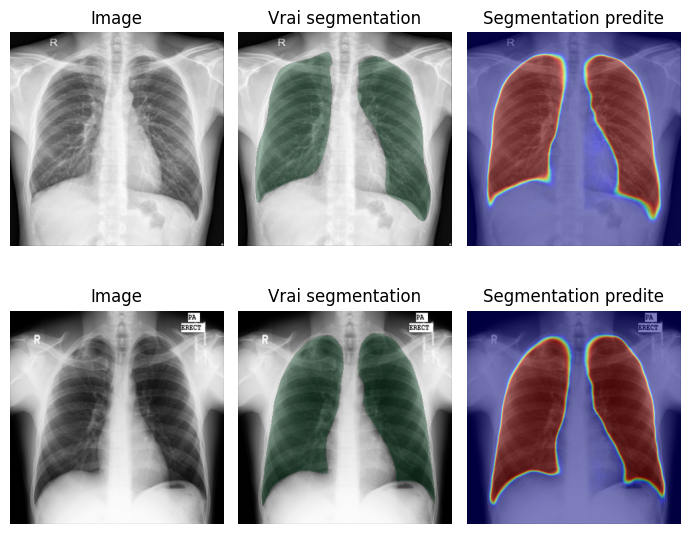

In [100]:
# Using an in-memory model:
#plot_random_lung_overlays(test_ds, model=net, num_images=3, alpha_gt=0.35, alpha_pred=0.35)

# Loading a specific epoch/checkpoint:
#plot_random_lung_overlays(test_ds, weights_path="checkpoint_epoch_009.pt", num_images=3)

# If you want more (or less) opacity:
#plot_random_lung_overlays(test_ds, model=net, num_images=3, alpha_gt=0.25, alpha_pred=0.5)

#Probabilities overlay (smooth heatmap):
plot_random_lung_overlays(test_ds, weights_path="checkpoint_epoch_013.pt", num_images=2, alpha_pred=0.5, binarize_pred=False)

#Binary overlay at 0.5 with inferno colormap:
#plot_random_lung_overlays(test_ds, model=net, num_images=3,
#                          binarize_pred=True, pred_threshold=0.5, alpha_pred=0.5)




In [113]:
import random, torch, numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec

@torch.inference_mode()
def plot_lung_and_classification_panels(
    dataset,
    *,
    model=None,
    weights_path: str | None = None,
    num_images: int = 3,
    indices: list[int] | None = None,      # optionally choose exact indices
    alpha_gt: float = 0.35,
    alpha_pred: float = 0.35,
    binarize_pred_mask: bool = False,
    pred_mask_threshold: float = 0.5,
    cls_binary_threshold: float = 0.5,      # threshold to mark bars as "binary=1"
    seed: int | None = None,
):
    """
    For each chosen sample, produces a 2-row panel:
      Row 1 (3 cols): [Image | Image + GT lung overlay | Image + Pred lung overlay (inferno)]
      Row 2 (1 wide): GT class label (text) + bar chart of multiclass probabilities (with binary marks)

    Requires dataset items with keys:
      - "image": (3,H,W) normalized with your infer_tf (mean=std=0.5)
      - "lung_mask": (1,H,W)  binary mask (optional: sample skipped if absent/empty)
      - "label": int class index (for CE); used as GT label text in the chart

    Uses model outputs:
      - out["organs"][:, 1] for lung probability
      - out["logits"] for multiclass probs via softmax
    """
    # ---- device resolution (uses your globals if present) ----
    if "DEVICE" in globals():
        dev = DEVICE
    elif "device" in globals():
        dev = device
    else:
        dev = torch.device("mps" if torch.backends.mps.is_available()
                           else "cuda" if torch.cuda.is_available()
                           else "cpu")

    # ---- choose/load model ----
    if model is None:
        if weights_path is None:
            model = load_model(num_classes=NUM_CLASSES, img_size=IMG_SIZE)
        else:
            model = safe_load_for_eval(weights_path, num_classes=NUM_CLASSES, img_size=IMG_SIZE)
    model = model.to(dev).eval()

    # ---- choose indices that have lung masks ----
    if indices is None:
        rng = random.Random(seed)
        all_idx = list(range(len(dataset)))
        rng.shuffle(all_idx)
        chosen = []
        for i in all_idx:
            s = dataset[i]
            lm = s.get("lung_mask", None)
            if lm is not None and lm.sum().item() > 0:
                chosen.append(i)
            if len(chosen) >= num_images:
                break
    else:
        chosen = indices[:num_images]

    if not chosen:
        print("No samples with 'lung_mask' found in dataset.")
        return

    # ---- build batch ----
    xb, gts, gtlbls = [], [], []
    for i in chosen:
        s = dataset[i]
        xb.append(s["image"].unsqueeze(0))               # (1,3,H,W)
        gts.append(s["lung_mask"].float().unsqueeze(0))  # (1,1,H,W)
        # CE setup uses integer label
        gtlbls.append(int(s["label"]) if "label" in s else None)

    xb = torch.cat(xb, 0).to(dev)  # (N,3,H,W)
    gt = torch.cat(gts, 0).to(dev) # (N,1,H,W)
    N = xb.size(0)

    # ---- forward ----
    out = model(xb)
    lungs_prob = torch.sigmoid(out["organs"][:, 1:2])   # (N,1,H,W)
    logits = out["logits"]                               # (N,K)
    probs = torch.softmax(logits, dim=1).detach().cpu().numpy()  # (N,K)
    probs = torch.sigmoid(logits).detach().cpu().numpy()  # (N,K)

    # ---- helpers ----
    def denorm_first_channel(x3hw: torch.Tensor) -> np.ndarray:
        return (x3hw[0].clamp(-1, 1) * 0.5 + 0.5).detach().cpu().numpy()

    gt_bin = (gt >= 0.5).float()

    # ---- figure: for each sample, make a 2-row GridSpec block ----
    fig = plt.figure(figsize=(12, 4 * N))
    outer = gridspec.GridSpec(N, 1, hspace=0.5, figure=fig)

    for r in range(N):
        # Sub-grid: 2 rows, top = 3 columns images, bottom = 1 wide bar chart
        gs = gridspec.GridSpecFromSubplotSpec(2, 3, subplot_spec=outer[r], height_ratios=[1.0, 0.9], hspace=0.25)

        # ----- Row 1: three image panels -----
        img_np = denorm_first_channel(xb[r])
        gt_np  = gt_bin[r, 0].detach().cpu().numpy()
        pr_np  = lungs_prob[r, 0].detach().cpu().numpy()
        if binarize_pred_mask:
            pr_np = (pr_np >= pred_mask_threshold).astype(np.float32)

        # Col 1: original
        ax1 = fig.add_subplot(gs[0, 0])
        ax1.imshow(img_np, cmap="gray"); ax1.set_title("Image"); ax1.axis("off")

        # Col 2: GT overlay (green)
        ax2 = fig.add_subplot(gs[0, 1])
        ax2.imshow(img_np, cmap="gray")
        ax2.imshow(np.ma.masked_where(gt_np == 0, gt_np), cmap="Greens", alpha=alpha_gt, vmin=0, vmax=1)
        ax2.set_title("GT lungs"); ax2.axis("off")

        # Col 3: Pred overlay (inferno)
        ax3 = fig.add_subplot(gs[0, 2])
        ax3.imshow(img_np, cmap="gray")
        ax3.imshow(pr_np, cmap="inferno", alpha=alpha_pred, vmin=0, vmax=1)
        ax3.set_title("Pred lungs"); ax3.axis("off")

        # ----- Row 2: text GT label + bar chart of probs -----
        axbar = fig.add_subplot(gs[1, :])  # span all 3 columns
        K = probs.shape[1]
        xs = np.arange(K)
        vals = probs[r]

        # bar chart
        bars = axbar.bar(xs, vals)
        axbar.set_ylim(0, 1.0)
        axbar.set_xticks(xs)
        axbar.set_xticklabels(CLASS_NAMES if 'CLASS_NAMES' in globals() else [str(i) for i in range(K)],
                              rotation=45, ha="right")
        axbar.set_ylabel("Probability")
        axbar.set_title("Classification — multiclass probabilities (+ binary marks)")

        # binary marks (≥ threshold)
        bin_mask = (vals >= cls_binary_threshold)
        for j, b in enumerate(bars):
            if bin_mask[j]:
                b.set_hatch("//")
                b.set_edgecolor("k")
                b.set_linewidth(1.0)

        # annotate max prob
        jmax = int(vals.argmax())
        axbar.text(jmax, min(0.98, vals[jmax] + 0.03), f"{vals[jmax]:.2f}", ha="center", va="bottom", fontsize=9)

        # GT label text
        gt_idx = gtlbls[r]
        gt_name = CLASS_NAMES[gt_idx] if (gt_idx is not None and 'CLASS_NAMES' in globals()) else str(gt_idx)
        axbar.text(0.01, 1.05, f"GT label: {gt_name}", transform=axbar.transAxes, ha="left", va="bottom", fontsize=11)

        # predicted top-1 text
        pred_name = CLASS_NAMES[jmax] if 'CLASS_NAMES' in globals() else str(jmax)
        axbar.text(0.99, 1.05, f"Pred (top-1): {pred_name}", transform=axbar.transAxes, ha="right", va="bottom", fontsize=11)

    plt.tight_layout()
    plt.show()


/var/folders/x8/r488q5111f96th7wf52rtb9r0000gn/T/ipykernel_8831/1096783587.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


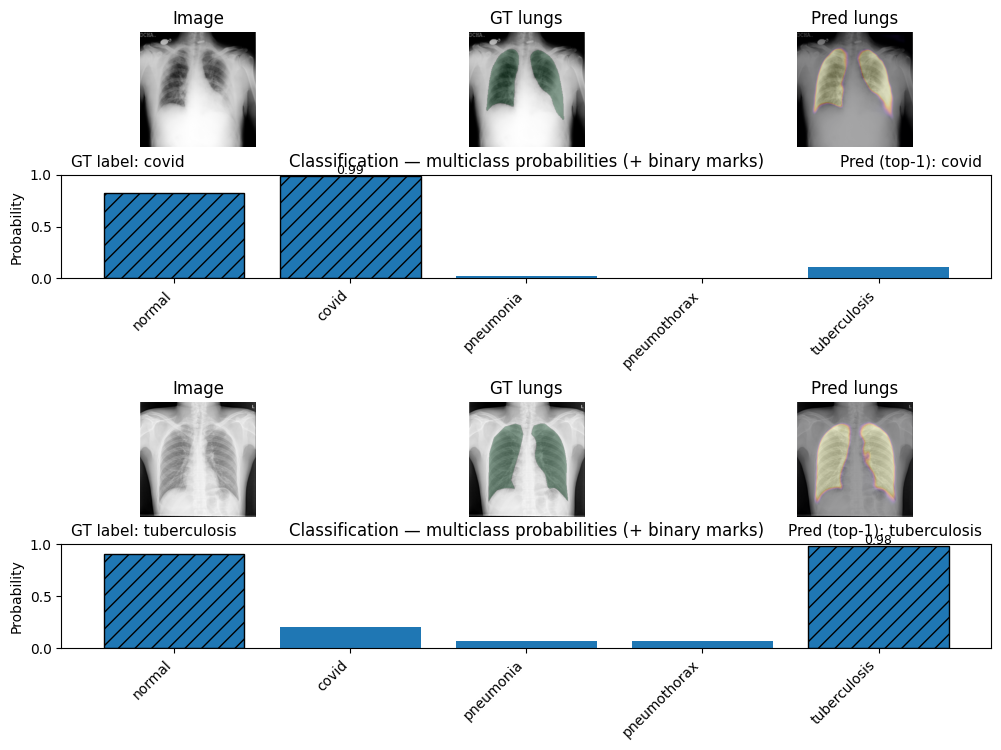

In [140]:
# Using an in-memory model, 3 random samples with lung masks
#plot_lung_and_classification_panels(test_ds, model=net, num_images=3)

# Same, but show hard predicted lung mask (inferno) at 0.5
#plot_lung_and_classification_panels(test_ds, model=net, num_images=3,
#                                    binarize_pred_mask=True, pred_mask_threshold=0.5)

# From a specific epoch file
plot_lung_and_classification_panels(test_ds, weights_path="checkpoint_epoch_009.pt", num_images=2)
